In [2]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU(s):", gpus)

if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

    print("GPU available: Yes")
    print("GPU count:", len(gpus))
else:
    print("GPU available: No")

print("\nDataset directory exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("\nDataset contents:")
    for item in sorted(os.listdir(DATA_DIR)):
        path = os.path.join(DATA_DIR, item)
        if os.path.isdir(path):
            print(f"  [DIR]  {item}")
        else:
            print(f"  [FILE] {item}")

print("\nRandom seed:", SEED)

TensorFlow: 2.20.0
Keras: 3.13.2
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU available: Yes
GPU count: 2

Dataset directory exists: True

Dataset contents:
  [DIR]  HAM10000_images_part_1
  [DIR]  HAM10000_images_part_2
  [FILE] HAM10000_metadata.csv
  [DIR]  ham10000_images_part_1
  [DIR]  ham10000_images_part_2
  [FILE] hmnist_28_28_L.csv
  [FILE] hmnist_28_28_RGB.csv
  [FILE] hmnist_8_8_L.csv
  [FILE] hmnist_8_8_RGB.csv

Random seed: 42


In [3]:
import os
import pandas as pd

metadata_path = os.path.join(DATA_DIR, "HAM10000_metadata.csv")

metadata = pd.read_csv(metadata_path)

print("Metadata shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

print("\nClass distribution:")
print(metadata["dx"].value_counts().sort_index())

print("\nClass names:")
print(sorted(metadata["dx"].unique()))

image_dirs = [
    os.path.join(DATA_DIR, "HAM10000_images_part_1"),
    os.path.join(DATA_DIR, "HAM10000_images_part_2"),
    os.path.join(DATA_DIR, "ham10000_images_part_1"),
    os.path.join(DATA_DIR, "ham10000_images_part_2"),
]

print("\nImage folder verification:")

for folder in image_dirs:
    if os.path.exists(folder):
        jpg_count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg"))
        )
        print(f"{os.path.basename(folder)}: {jpg_count} JPG images")
    else:
        print(f"{os.path.basename(folder)}: NOT FOUND")

print("\nMetadata columns preview:")
print(metadata[["image_id", "dx"]].head())

print("\nMissing values:")
print(metadata[["image_id", "dx"]].isnull().sum())

print("\nUnique image IDs:", metadata["image_id"].nunique())
print("Total metadata rows:", len(metadata))

Metadata shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Class distribution:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64

Class names:
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

Image folder verification:
HAM10000_images_part_1: 5000 JPG images
HAM10000_images_part_2: 5015 JPG images
ham10000_images_part_1: 5000 JPG images
ham10000_images_part_2: 5015 JPG images

Metadata columns preview:
       image_id   dx
0  ISIC_0027419  bkl
1  ISIC_0025030  bkl
2  ISIC_0026769  bkl
3  ISIC_0025661  bkl
4  ISIC_0031633  bkl

Missing values:
image_id    0
dx          0
dtype: int64

Unique image IDs: 10015
Total metadata rows: 10015


In [4]:
from collections import defaultdict

# Find all original JPG images
image_folders = [
    os.path.join(DATA_DIR, "HAM10000_images_part_1"),
    os.path.join(DATA_DIR, "HAM10000_images_part_2"),
    os.path.join(DATA_DIR, "ham10000_images_part_1"),
    os.path.join(DATA_DIR, "ham10000_images_part_2"),
]

image_map = defaultdict(list)

for folder in image_folders:
    if not os.path.isdir(folder):
        continue

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg")):
            image_id = os.path.splitext(filename)[0]
            image_map[image_id].append(os.path.join(folder, filename))

print("Unique JPG image IDs found:", len(image_map))

# Check whether any image ID exists in multiple folders
duplicate_ids = {
    image_id: paths
    for image_id, paths in image_map.items()
    if len(paths) > 1
}

print("Image IDs found in multiple folders:", len(duplicate_ids))

if duplicate_ids:
    print("\nExample duplicate image IDs:")
    for image_id, paths in list(duplicate_ids.items())[:5]:
        print(image_id)
        for path in paths:
            print("  ", path)

# Use one path per image ID
# Preference is given to the first discovered valid JPG.
metadata["image_path"] = metadata["image_id"].map(
    lambda x: image_map[x][0] if x in image_map else None
)

missing_images = metadata["image_path"].isna().sum()

print("\nMetadata records:", len(metadata))
print("Records with valid JPG:", len(metadata) - missing_images)
print("Records missing JPG:", missing_images)

if missing_images == 0:
    print("\n✓ Every metadata record has an original JPG image.")
else:
    print("\n⚠ Missing image IDs:")
    print(metadata.loc[metadata["image_path"].isna(), "image_id"].head(20).tolist())

# Verify the seven classes
class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

print("\nClass mapping:")
for i, class_name in enumerate(class_names):
    count = (metadata["dx"] == class_name).sum()
    print(f"{i}: {class_name:<5} -> {count}")

print("\nSample image paths:")
print(metadata[["image_id", "dx", "image_path"]].head(5).to_string(index=False))

Unique JPG image IDs found: 10015
Image IDs found in multiple folders: 10015

Example duplicate image IDs:
ISIC_0028933
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028933.jpg
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1/ISIC_0028933.jpg
ISIC_0028394
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028394.jpg
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1/ISIC_0028394.jpg
ISIC_0027799
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027799.jpg
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1/ISIC_0027799.jpg
ISIC_0028100
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028100.jpg
   /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1/ISIC_0028100.jpg
ISIC_0027960
   /kaggle/input/datasets/km

In [5]:
from sklearn.model_selection import train_test_split

# Keep only the required columns
df = metadata[["image_id", "image_path", "dx"]].copy()

# Fixed class order
class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

df["label"] = df["dx"].map(class_to_index)

# First split: 80% development data, 20% untouched test data
train_val_df, test_df = train_test_split(
    df,
    train_size=8012,
    test_size=2003,
    stratify=df["label"],
    random_state=42,
    shuffle=True
)

# Second split: 7010 training, 1002 validation
train_df, val_df = train_test_split(
    train_val_df,
    train_size=7010,
    test_size=1002,
    stratify=train_val_df["label"],
    random_state=42,
    shuffle=True
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Dataset split:")
print(f"Train      : {len(train_df)}")
print(f"Validation : {len(val_df)}")
print(f"Test       : {len(test_df)}")
print(f"Total      : {len(train_df) + len(val_df) + len(test_df)}")

print("\nClass distribution:")
print("\nTrain:")
print(train_df["dx"].value_counts().reindex(class_names))

print("\nValidation:")
print(val_df["dx"].value_counts().reindex(class_names))

print("\nTest:")
print(test_df["dx"].value_counts().reindex(class_names))

print("\nClass proportions:")
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    proportions = (
        split_df["dx"]
        .value_counts(normalize=True)
        .reindex(class_names)
        .round(4)
    )
    print(f"\n{split_name}:")
    print(proportions)

print("\nSplit sizes verified:")
assert len(train_df) == 7010
assert len(val_df) == 1002
assert len(test_df) == 2003
assert len(train_df) + len(val_df) + len(test_df) == 10015

print("✓ Fixed stratified split created successfully.")
print("✓ Test set will remain untouched.")

Dataset split:
Train      : 7010
Validation : 1002
Test       : 2003
Total      : 10015

Class distribution:

Train:
dx
akiec     229
bcc       360
bkl       769
df         80
mel       779
nv       4693
vasc      100
Name: count, dtype: int64

Validation:
dx
akiec     33
bcc       51
bkl      110
df        12
mel      111
nv       671
vasc      14
Name: count, dtype: int64

Test:
dx
akiec      65
bcc       103
bkl       220
df         23
mel       223
nv       1341
vasc       28
Name: count, dtype: int64

Class proportions:

Train:
dx
akiec    0.0327
bcc      0.0514
bkl      0.1097
df       0.0114
mel      0.1111
nv       0.6695
vasc     0.0143
Name: proportion, dtype: float64

Validation:
dx
akiec    0.0329
bcc      0.0509
bkl      0.1098
df       0.0120
mel      0.1108
nv       0.6697
vasc     0.0140
Name: proportion, dtype: float64

Test:
dx
akiec    0.0325
bcc      0.0514
bkl      0.1098
df       0.0115
mel      0.1113
nv       0.6695
vasc     0.0140
Name: proportion, dtype: float

In [6]:
import gc
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = 7
AUTOTUNE = tf.data.AUTOTUNE

MODEL_NAME = "EfficientNetB0"

MODEL_CONFIG = {
    "EfficientNetB0": {
        "input_size": 224,
        "batch_size": 32
    },
    "EfficientNetB1": {
        "input_size": 240,
        "batch_size": 32
    },
    "EfficientNetB2": {
        "input_size": 260,
        "batch_size": 24
    },
    "EfficientNetB3": {
        "input_size": 300,
        "batch_size": 16
    },
    "EfficientNetB4": {
        "input_size": 380,
        "batch_size": 8
    },
    "EfficientNetB5": {
        "input_size": 456,
        "batch_size": 4
    },
    "EfficientNetB6": {
        "input_size": 528,
        "batch_size": 2
    },
    "EfficientNetB7": {
        "input_size": 600,
        "batch_size": 1
    }
}

config = MODEL_CONFIG[MODEL_NAME]

print("Current model:", MODEL_NAME)
print("Input size:", config["input_size"])
print("Batch size:", config["batch_size"])
print("Number of classes:", NUM_CLASSES)
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

Current model: EfficientNetB0
Input size: 224
Batch size: 32
Number of classes: 7
Training samples: 7010
Validation samples: 1002
Test samples: 2003


In [6]:
from tensorflow.keras.applications.efficientnet import preprocess_input

IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

# Training-only augmentation
train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10),
], name="train_augmentation")


def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method=tf.image.ResizeMethod.BILINEAR
    )
    image = tf.cast(image, tf.float32)

    # EfficientNet preprocessing
    image = preprocess_input(image)

    return image, label


def load_train_image(image_path, label):
    image, label = load_image(image_path, label)

    # Augmentation is applied only to training images
    image = train_augmentation(image, training=True)

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            load_train_image,
            num_parallel_calls=AUTOTUNE
        )
    else:
        dataset = dataset.map(
            load_image,
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)
test_ds = create_dataset(test_df, training=False)

# Verify one training batch
train_images, train_labels = next(iter(train_ds))

print("Training batch:")
print("Images shape:", train_images.shape)
print("Labels shape:", train_labels.shape)
print("Image dtype:", train_images.dtype)
print("Image min:", float(tf.reduce_min(train_images)))
print("Image max:", float(tf.reduce_max(train_images)))
print("Labels:", train_labels.numpy()[:10])

# Verify validation batch
val_images, val_labels = next(iter(val_ds))

print("\nValidation batch:")
print("Images shape:", val_images.shape)
print("Labels shape:", val_labels.shape)

# Verify test batch
test_images, test_labels = next(iter(test_ds))

print("\nTest batch:")
print("Images shape:", test_images.shape)
print("Labels shape:", test_labels.shape)

# Sanity checks
assert train_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert val_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert test_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)

assert train_labels.dtype == tf.int32
assert val_labels.dtype == tf.int32
assert test_labels.dtype == tf.int32

print("\n✓ B0 image pipeline verified successfully.")
print("✓ Original JPG images are being used.")
print("✓ Augmentation is applied only to training.")
print("✓ Validation and test data are not augmented.")

I0000 00:00:1788844756.541509      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788844756.544513      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Training batch:
Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image dtype: <dtype: 'float32'>
Image min: 0.0
Image max: 255.0
Labels: [5 4 5 4 1 5 5 2 5 5]

Validation batch:
Images shape: (32, 224, 224, 3)
Labels shape: (32,)

Test batch:
Images shape: (32, 224, 224, 3)
Labels shape: (32,)

✓ B0 image pipeline verified successfully.
✓ Original JPG images are being used.
✓ Augmentation is applied only to training.
✓ Validation and test data are not augmented.


In [7]:
from tensorflow.keras.applications import EfficientNetB0

# Build ImageNet-pretrained EfficientNetB0
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_HAM10000"
)

model.summary()

print("\nBackbone trainable:", base_model.trainable)
print("Total parameters:", model.count_params())
print("Trainable parameters:", sum(
    np.prod(variable.shape)
    for variable in model.trainable_variables
))
print("Non-trainable parameters:", sum(
    np.prod(variable.shape)
    for variable in model.non_trainable_variables
))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_HAM10000"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Backbone trainable: False
Total parameters: 4058538
Trainable parameters: 8967
Non-trainable parameters: 4049591.0


In [8]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")
print("Optimizer: Adam")
print("Learning rate: 1e-3")
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")
print("Backbone frozen:", not base_model.trainable)

Model compiled successfully.
Optimizer: Adam
Learning rate: 1e-3
Loss: Sparse Categorical Crossentropy
Metric: Accuracy
Backbone frozen: True


In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

B0_HEAD_PATH = "/kaggle/working/efficientnetb0_head_best.keras"

head_callbacks = [
    ModelCheckpoint(
        B0_HEAD_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Starting EfficientNetB0 head training...")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Backbone frozen:", not base_model.trainable)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=head_callbacks,
    verbose=1
)

best_head_val_acc = max(history_head.history["val_accuracy"])

print("\nB0 head training complete.")
print(f"Best validation accuracy: {best_head_val_acc * 100:.2f}%")
print(f"Best checkpoint: {B0_HEAD_PATH}")

Starting EfficientNetB0 head training...
Training samples: 7010
Validation samples: 1002
Backbone frozen: True
Epoch 1/10


2026-09-08 05:21:20.878650: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:21:21.022043: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:21:21.371944: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:21:21.514367: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:21:21.656283: E external/local_xla/xla/stream_

219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.6359 - loss: 1.0969

2026-09-08 05:22:49.599153: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:22:49.732306: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:22:50.040602: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:22:50.181946: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:22:50.956088: E external/local_xla/xla/stream_

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.6360 - loss: 1.0962

2026-09-08 05:23:12.780270: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:23:12.917023: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:23:13.228976: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:23:13.369726: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 05:23:14.150200: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.69461, saving model to /kaggle/working/efficientnetb0_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb0_head_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 138s 497ms/step - accuracy: 0.6753 - loss: 0.9496 - val_accuracy: 0.6946 - val_loss: 0.8335 - learning_rate: 0.0010
Epoch 2/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step - accuracy: 0.7173 - loss: 0.7950
Epoch 2: val_accuracy improved from 0.69461 to 0.71158, saving model to /kaggle/working/efficientnetb0_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb0_head_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 67s 304ms/step - accuracy: 0.7128 - loss: 0.7914 - val_accuracy: 0.7116 - val_loss: 0.7782 - learning_rate: 0.0010
Epoch 3/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.7272 - loss: 0.7359
Epoch 3: val_accuracy improved from 0.71158 to 0.72255, saving model to /kaggle/working/efficientnetb0_head_best.keras

Epoch 3: finish

In [10]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Start from the best frozen-backbone checkpoint
model.load_weights(B0_HEAD_PATH)

# Freeze most of the backbone and fine-tune the upper layers
base_model.trainable = True

fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

B0_FINE_TUNE_PATH = "/kaggle/working/efficientnetb0_best.keras"

fine_tune_callbacks = [
    ModelCheckpoint(
        B0_FINE_TUNE_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

trainable_count = sum(
    np.prod(variable.shape)
    for variable in model.trainable_variables
)

print("Starting EfficientNetB0 fine-tuning...")
print("Fine-tuning from layer:", fine_tune_from)
print("Total backbone layers:", len(base_model.layers))
print("Trainable parameters:", trainable_count)
print("Learning rate:", 1e-5)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=fine_tune_callbacks,
    verbose=1
)

best_fine_val_acc = max(history_fine.history["val_accuracy"])

print("\nB0 fine-tuning complete.")
print(f"Best fine-tuning validation accuracy: {best_fine_val_acc * 100:.2f}%")
print(f"Best B0 model: {B0_FINE_TUNE_PATH}")

Starting EfficientNetB0 fine-tuning...
Fine-tuning from layer: 166
Total backbone layers: 238
Trainable parameters: 3063587
Learning rate: 1e-05
Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step - accuracy: 0.7669 - loss: 0.6421
Epoch 1: val_accuracy improved from None to 0.76248, saving model to /kaggle/working/efficientnetb0_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb0_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 122s 425ms/step - accuracy: 0.7716 - loss: 0.6268 - val_accuracy: 0.7625 - val_loss: 0.6319 - learning_rate: 1.0000e-05
Epoch 2/20
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - accuracy: 0.7767 - loss: 0.6076
Epoch 2: val_accuracy did not improve from 0.76248
220/220 ━━━━━━━━━━━━━━━━━━━━ 70s 318ms/step - accuracy: 0.7807 - loss: 0.5991 - val_accuracy: 0.7625 - val_loss: 0.6204 - learning_rate: 1.0000e-05
Epoch 3/20
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.7902 - loss: 0.5755
Epoch 3: val_accuracy improved from 0.76248 to 0.77246,

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the best B0 checkpoint
model.load_weights(B0_FINE_TUNE_PATH)

print("Evaluating best EfficientNetB0 checkpoint...")
print("Test samples:", len(test_df))

# Test loss and Keras accuracy
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

# Generate predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)
f1_weighted = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)
f1_macro = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("\nEfficientNetB0 Test Results")
print("-" * 40)
print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {accuracy * 100:.2f}%")
print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"F1 Score        : {f1_weighted * 100:.2f}%")
print(f"Macro F1        : {f1_macro * 100:.2f}%")

print("\nClassification Report")
print("-" * 60)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix")
print("-" * 60)
print(confusion_matrix(y_true, y_pred))

print("\n✓ B0 test evaluation complete.")
print("✓ Test set was used only for final evaluation.")

Evaluating best EfficientNetB0 checkpoint...
Test samples: 2003
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.8030 - loss: 0.5329

2026-09-08 06:00:03.527247: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:00:03.667439: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:00:04.004646: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:00:04.145731: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:00:04.927537: E external/local_xla/xla/stream_

63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 289ms/step - accuracy: 0.8113 - loss: 0.5260

EfficientNetB0 Test Results
----------------------------------------
Test Loss       : 0.5260
Test Accuracy   : 81.13%
Precision       : 81.31%
Recall          : 81.13%
F1 Score        : 80.31%
Macro F1        : 63.34%

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

       akiec     0.8750    0.3231    0.4719        65
         bcc     0.7838    0.5631    0.6554       103
         bkl     0.5578    0.7682    0.6463       220
          df     0.5294    0.3913    0.4500        23
         mel     0.5767    0.4215    0.4870       223
          nv     0.8945    0.9359    0.9147      1341
        vasc     1.0000    0.6786    0.8085        28

    accuracy                         0.8113      2003
   macro avg     0.7453    0.5831    0.6334      2003
weighted avg     0.8131    0.8113    0.8031      2003


Confusion Matrix
-----

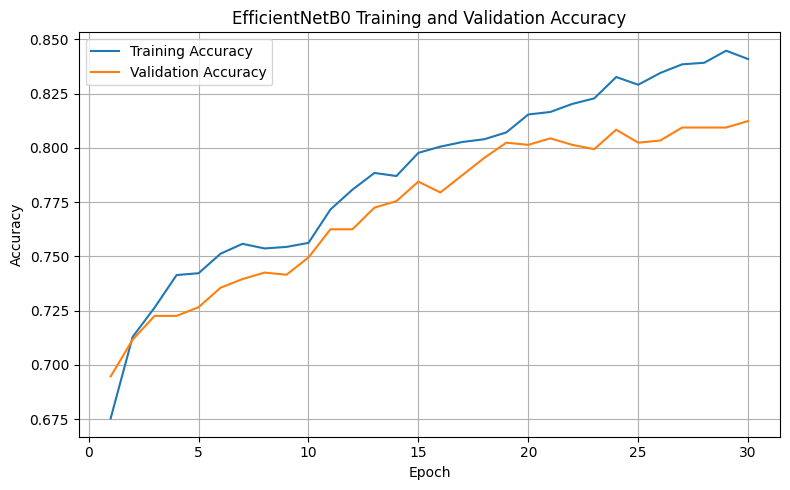

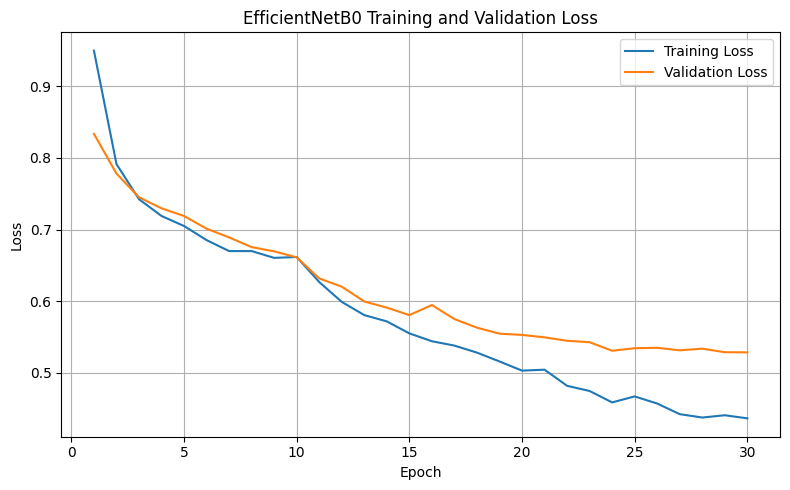

EfficientNetB0 results saved.
Best Validation Accuracy : 81.24%
Test Accuracy            : 81.13%
Macro F1                 : 63.34%
Weighted F1              : 80.31%
Accuracy plot            : /kaggle/working/efficientnetb0_accuracy.png
Loss plot                : /kaggle/working/efficientnetb0_loss.png
Results CSV              : /kaggle/working/efficientnetb0_results.csv


In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Combine Stage 1 and Stage 2 training history
train_acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]

train_loss = history_head.history["loss"] + history_fine.history["loss"]
val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]

epochs = range(1, len(train_acc) + 1)

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB0 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

b0_acc_plot = "/kaggle/working/efficientnetb0_accuracy.png"
plt.savefig(b0_acc_plot, dpi=200)
plt.show()

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB0 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

b0_loss_plot = "/kaggle/working/efficientnetb0_loss.png"
plt.savefig(b0_loss_plot, dpi=200)
plt.show()

# Save B0 results
b0_result = {
    "Model": "EfficientNetB0",
    "Parameters": model.count_params(),
    "Input Size": f"{IMG_SIZE}x{IMG_SIZE}",
    "Best Val Accuracy": max(val_acc),
    "Test Accuracy": accuracy,
    "Test Loss": test_loss,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_weighted,
    "Macro F1": f1_macro
}

b0_results_df = pd.DataFrame([b0_result])
b0_results_df.to_csv(
    "/kaggle/working/efficientnetb0_results.csv",
    index=False
)

print("EfficientNetB0 results saved.")
print(f"Best Validation Accuracy : {max(val_acc) * 100:.2f}%")
print(f"Test Accuracy            : {accuracy * 100:.2f}%")
print(f"Macro F1                 : {f1_macro * 100:.2f}%")
print(f"Weighted F1              : {f1_weighted * 100:.2f}%")
print(f"Accuracy plot            : {b0_acc_plot}")
print(f"Loss plot                : {b0_loss_plot}")
print("Results CSV              : /kaggle/working/efficientnetb0_results.csv")

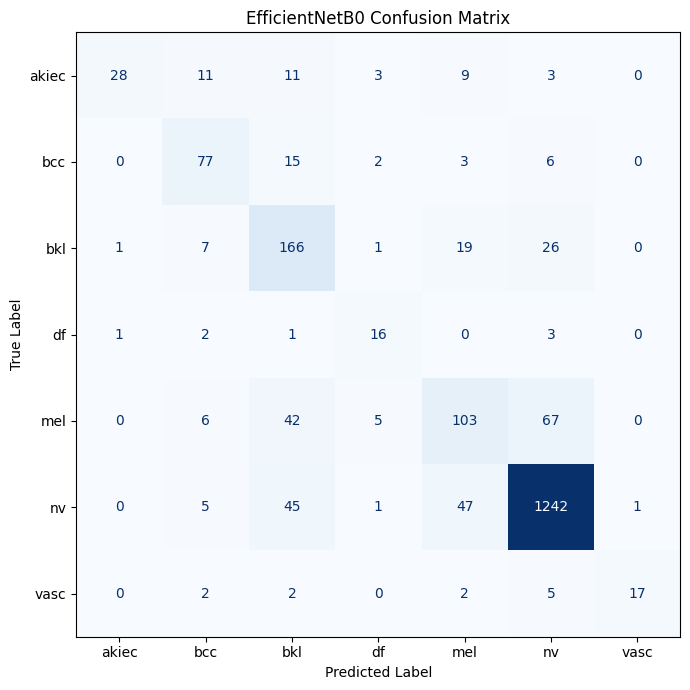

Confusion matrix saved: /kaggle/working/efficientnetb0_confusion_matrix.png


In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=plt.gca(),
    colorbar=False
)

plt.title("EfficientNetB0 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

b0_cm_plot = "/kaggle/working/efficientnetb0_confusion_matrix.png"
plt.savefig(b0_cm_plot, dpi=200, bbox_inches="tight")
plt.show()

print(f"Confusion matrix saved: {b0_cm_plot}")

EfficientNetB1****

In [13]:
MODEL_NAME = "EfficientNetB1"

config = MODEL_CONFIG[MODEL_NAME]

IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

print("Current model :", MODEL_NAME)
print("Input size    :", IMG_SIZE)
print("Batch size    :", BATCH_SIZE)
print("Training      :", len(train_df))
print("Validation    :", len(val_df))
print("Test          :", len(test_df))

Current model : EfficientNetB1
Input size    : 240
Batch size    : 32
Training      : 7010
Validation    : 1002
Test          : 2003


In [14]:
from tensorflow.keras.applications.efficientnet import preprocess_input

train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10),
], name="train_augmentation")

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method=tf.image.ResizeMethod.BILINEAR
    )
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

def load_train_image(image_path, label):
    image, label = load_image(image_path, label)
    image = train_augmentation(image, training=True)
    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            load_train_image,
            num_parallel_calls=AUTOTUNE
        )
    else:
        dataset = dataset.map(
            load_image,
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)
test_ds = create_dataset(test_df, training=False)

train_images, train_labels = next(iter(train_ds))
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("EfficientNetB1 pipeline ready")
print("Training batch :", train_images.shape, train_labels.shape)
print("Validation batch:", val_images.shape, val_labels.shape)
print("Test batch     :", test_images.shape, test_labels.shape)
print("Image dtype    :", train_images.dtype)
print("Image range    :", float(tf.reduce_min(train_images)),
      "to", float(tf.reduce_max(train_images)))

assert train_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert val_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert test_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)

print("B1 pipeline checks passed")
print("Training augmentation enabled only for training")
print("Validation/test remain unaugmented")

EfficientNetB1 pipeline ready
Training batch : (32, 240, 240, 3) (32,)
Validation batch: (32, 240, 240, 3) (32,)
Test batch     : (32, 240, 240, 3) (32,)
Image dtype    : <dtype: 'float32'>
Image range    : 0.0 to 255.0
B1 pipeline checks passed
Training augmentation enabled only for training
Validation/test remain unaugmented


In [15]:
from tensorflow.keras.applications import EfficientNetB1

base_model = EfficientNetB1(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB1_HAM10000"
)

model.summary()

print("\nBackbone trainable:", base_model.trainable)
print("Total parameters:", model.count_params())
print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w) for w in model.trainable_weights))

27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB1_HAM10000"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb1 (Functional)     │ (None, 8, 8, 1280)     │     6,575,239 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,584,206 (25.12 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 6,575,239 (25.08 MB)


Backbone trainable: False
Total parameters: 6584206
Trainable parameters: 8967


In [16]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB1 compiled")
print("Optimizer       : Adam")
print("Learning rate   : 1e-3")
print("Loss            : Sparse Categorical Crossentropy")
print("Metric          : Accuracy")
print("Backbone frozen :", not base_model.trainable)

EfficientNetB1 compiled
Optimizer       : Adam
Learning rate   : 1e-3
Loss            : Sparse Categorical Crossentropy
Metric          : Accuracy
Backbone frozen : True


In [17]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

B1_HEAD_PATH = "/kaggle/working/efficientnetb1_head_best.keras"

head_callbacks = [
    ModelCheckpoint(
        B1_HEAD_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=head_callbacks,
    verbose=1
)

print("\nEfficientNetB1 head training complete.")
print(f"Best validation accuracy: "
      f"{max(history_head.history['val_accuracy']) * 100:.2f}%")
print(f"Best checkpoint: {B1_HEAD_PATH}")

Epoch 1/10


2026-09-08 06:07:26.708605: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:07:26.852981: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:07:27.180837: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:07:27.322397: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:07:27.464852: E external/local_xla/xla/stream_

219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.6057 - loss: 1.1418

2026-09-08 06:09:01.170354: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:01.304642: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:01.577728: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:01.718365: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:02.476963: E external/local_xla/xla/stream_

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.6060 - loss: 1.1410

2026-09-08 06:09:29.429378: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:29.566920: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:29.855476: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:29.996832: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:09:30.138679: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.69760, saving model to /kaggle/working/efficientnetb1_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb1_head_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 156s 539ms/step - accuracy: 0.6659 - loss: 0.9635 - val_accuracy: 0.6976 - val_loss: 0.8224 - learning_rate: 0.0010
Epoch 2/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.7115 - loss: 0.8088
Epoch 2: val_accuracy improved from 0.69760 to 0.70559, saving model to /kaggle/working/efficientnetb1_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb1_head_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 78s 355ms/step - accuracy: 0.7094 - loss: 0.7975 - val_accuracy: 0.7056 - val_loss: 0.7795 - learning_rate: 0.0010
Epoch 3/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - accuracy: 0.7147 - loss: 0.7642
Epoch 3: val_accuracy improved from 0.70559 to 0.71657, saving model to /kaggle/working/efficientnetb1_head_best.keras

Epoch 3: finish

In [18]:
B1_HEAD_PATH = "/kaggle/working/efficientnetb1_head_best.keras"
B1_FINE_TUNE_PATH = "/kaggle/working/efficientnetb1_best.keras"

model.load_weights(B1_HEAD_PATH)

# Unfreeze the later 30% of the EfficientNetB1 backbone
base_model.trainable = True

fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    ModelCheckpoint(
        B1_FINE_TUNE_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning EfficientNetB1")
print("Total backbone layers :", len(base_model.layers))
print("Fine-tuning from layer:", fine_tune_from)
print("Learning rate         : 1e-5")
print("Batch normalization   : frozen")

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=fine_tune_callbacks,
    verbose=1
)

print("\nEfficientNetB1 fine-tuning complete.")
print(
    f"Best fine-tuning validation accuracy: "
    f"{max(history_fine.history['val_accuracy']) * 100:.2f}%"
)
print(f"Best checkpoint: {B1_FINE_TUNE_PATH}")

Fine-tuning EfficientNetB1
Total backbone layers : 340
Fine-tuning from layer: 237
Learning rate         : 1e-5
Batch normalization   : frozen
Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.7559 - loss: 0.6680
Epoch 1: val_accuracy improved from None to 0.75848, saving model to /kaggle/working/efficientnetb1_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb1_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 154s 516ms/step - accuracy: 0.7665 - loss: 0.6378 - val_accuracy: 0.7585 - val_loss: 0.6333 - learning_rate: 1.0000e-05
Epoch 2/20
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 0.7787 - loss: 0.6085
Epoch 2: val_accuracy improved from 0.75848 to 0.76447, saving model to /kaggle/working/efficientnetb1_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb1_best.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 83s 377ms/step - accuracy: 0.7816 - loss: 0.6018 - val_accuracy: 0.7645 - val_loss: 0.6153 - learning_rate: 1.0000e-05
Epoch

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.load_weights(B1_FINE_TUNE_PATH)

print("Evaluating best EfficientNetB1 checkpoint...")
print("Test samples:", len(test_df))

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nEfficientNetB1 Test Results")
print("-" * 40)
print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {accuracy * 100:.2f}%")
print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"F1 Score        : {f1_weighted * 100:.2f}%")
print(f"Macro F1        : {f1_macro * 100:.2f}%")

print("\nClassification Report")
print("-" * 60)
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix")
print("-" * 60)
print(confusion_matrix(y_true, y_pred))

print("\n B1 test evaluation complete.")
print("Test set was used only for final evaluation.")

Evaluating best EfficientNetB1 checkpoint...
Test samples: 2003
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8035 - loss: 0.5442

2026-09-08 06:52:49.993623: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:52:50.135258: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:52:50.433203: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:52:50.574158: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 06:52:50.714442: E external/local_xla/xla/stream_

63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 293ms/step - accuracy: 0.8048 - loss: 0.5388

EfficientNetB1 Test Results
----------------------------------------
Test Loss       : 0.5388
Test Accuracy   : 80.48%
Precision       : 80.99%
Recall          : 80.48%
F1 Score        : 79.99%
Macro F1        : 61.92%

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

       akiec     0.7000    0.2154    0.3294        65
         bcc     0.7945    0.5631    0.6591       103
         bkl     0.5646    0.6955    0.6232       220
          df     0.7692    0.4348    0.5556        23
         mel     0.5105    0.5426    0.5261       223
          nv     0.9031    0.9247    0.9138      1341
        vasc     1.0000    0.5714    0.7273        28

    accuracy                         0.8048      2003
   macro avg     0.7489    0.5639    0.6192      2003
weighted avg     0.8099    0.8048    0.7999      2003


Confusion Matrix
-----

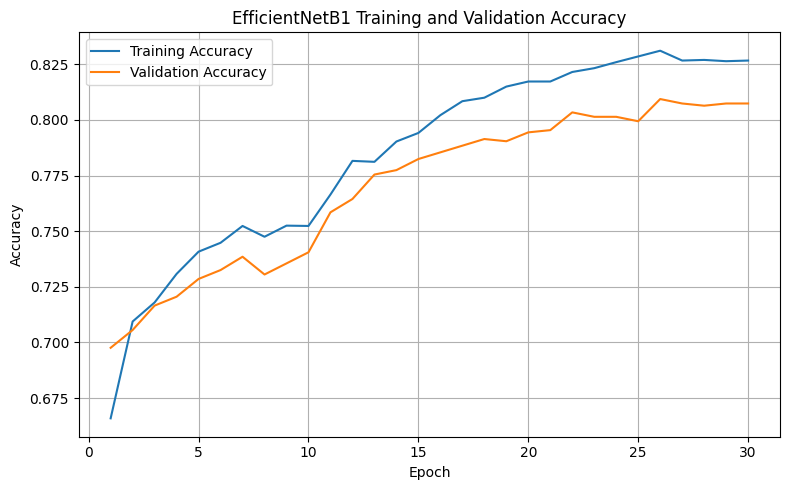

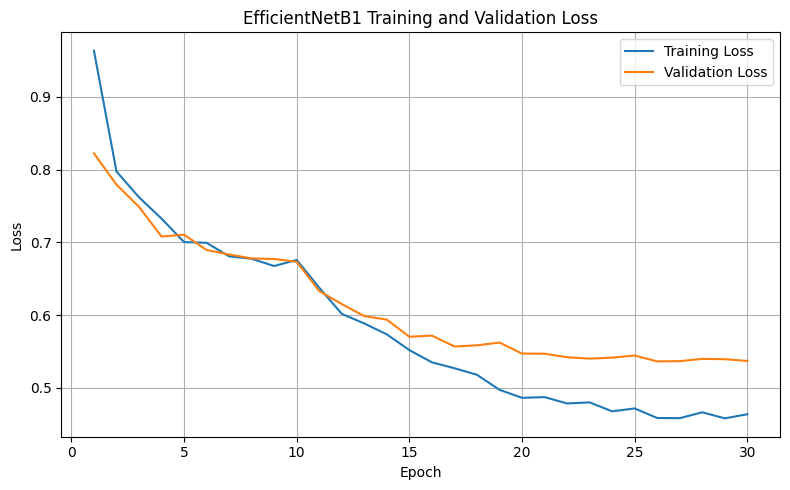

EfficientNetB1 results saved.
Best Validation Accuracy : 80.94%
Test Accuracy            : 80.48%
Macro F1                 : 61.92%
Weighted F1              : 79.99%
Accuracy plot            : /kaggle/working/efficientnetb1_accuracy.png
Loss plot                : /kaggle/working/efficientnetb1_loss.png
Results CSV              : /kaggle/working/efficientnetb1_results.csv


In [20]:
import matplotlib.pyplot as plt
import pandas as pd

train_acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]

train_loss = history_head.history["loss"] + history_fine.history["loss"]
val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]

epochs = range(1, len(train_acc) + 1)

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB1 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

b1_acc_plot = "/kaggle/working/efficientnetb1_accuracy.png"
plt.savefig(b1_acc_plot, dpi=200)
plt.show()

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

b1_loss_plot = "/kaggle/working/efficientnetb1_loss.png"
plt.savefig(b1_loss_plot, dpi=200)
plt.show()

# Save B1 results
b1_result = {
    "Model": "EfficientNetB1",
    "Parameters": model.count_params(),
    "Input Size": f"{IMG_SIZE}x{IMG_SIZE}",
    "Best Val Accuracy": max(val_acc),
    "Test Accuracy": accuracy,
    "Test Loss": test_loss,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_weighted,
    "Macro F1": f1_macro
}

b1_results_df = pd.DataFrame([b1_result])

b1_results_df.to_csv(
    "/kaggle/working/efficientnetb1_results.csv",
    index=False
)

print("EfficientNetB1 results saved.")
print(f"Best Validation Accuracy : {max(val_acc) * 100:.2f}%")
print(f"Test Accuracy            : {accuracy * 100:.2f}%")
print(f"Macro F1                 : {f1_macro * 100:.2f}%")
print(f"Weighted F1              : {f1_weighted * 100:.2f}%")
print(f"Accuracy plot            : {b1_acc_plot}")
print(f"Loss plot                : {b1_loss_plot}")
print("Results CSV              : /kaggle/working/efficientnetb1_results.csv")

In [32]:
from tensorflow.keras.applications import EfficientNetB1

B1_IMG_SIZE = 240

base_model_b1 = EfficientNetB1(
    include_top=False,
    weights="imagenet",
    input_shape=(B1_IMG_SIZE, B1_IMG_SIZE, 3)
)

inputs_b1 = keras.Input(
    shape=(B1_IMG_SIZE, B1_IMG_SIZE, 3),
    name="image"
)

x_b1 = base_model_b1(inputs_b1, training=False)
x_b1 = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x_b1)
x_b1 = layers.Dropout(0.30, name="dropout")(x_b1)
outputs_b1 = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x_b1)

model_b1 = keras.Model(
    inputs=inputs_b1,
    outputs=outputs_b1,
    name="EfficientNetB1_HAM10000"
)

print("EfficientNetB1 model rebuilt")
print("Input size :", B1_IMG_SIZE)
print("Parameters :", model_b1.count_params())

EfficientNetB1 model rebuilt
Input size : 240
Parameters : 6584206


In [33]:
b1_checkpoint = "/kaggle/working/efficientnetb1_best.keras"

model_b1.load_weights(b1_checkpoint)

y_true_b1 = []
y_pred_b1 = []

# B1 requires its own 240x240 test pipeline
test_ds_b1 = create_dataset(test_df, training=False)

# Recreate with B1 image size
def load_image_b1(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(
        image,
        [B1_IMG_SIZE, B1_IMG_SIZE],
        method=tf.image.ResizeMethod.BILINEAR
    )
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

test_ds_b1 = (
    tf.data.Dataset.from_tensor_slices(
        (
            test_df["image_path"].values,
            test_df["label"].values.astype("int32")
        )
    )
    .map(load_image_b1, num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

for images, labels in test_ds_b1:
    predictions = model_b1.predict(images, verbose=0)
    y_true_b1.extend(labels.numpy())
    y_pred_b1.extend(np.argmax(predictions, axis=1))

y_true_b1 = np.array(y_true_b1)
y_pred_b1 = np.array(y_pred_b1)

cm_b1 = confusion_matrix(y_true_b1, y_pred_b1)

print("EfficientNetB1 Confusion Matrix:")
print(cm_b1)

print("\nClassification Report:")
print(
    classification_report(
        y_true_b1,
        y_pred_b1,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

EfficientNetB1 Confusion Matrix:
[[  14    8   23    2   12    6    0]
 [   2   58   18    0   11   14    0]
 [   1    1  153    1   31   33    0]
 [   1    0    3   10    2    7    0]
 [   1    1   34    0  121   66    0]
 [   1    4   39    0   57 1240    0]
 [   0    1    1    0    3    7   16]]

Classification Report:
              precision    recall  f1-score   support

       akiec     0.7000    0.2154    0.3294        65
         bcc     0.7945    0.5631    0.6591       103
         bkl     0.5646    0.6955    0.6232       220
          df     0.7692    0.4348    0.5556        23
         mel     0.5105    0.5426    0.5261       223
          nv     0.9031    0.9247    0.9138      1341
        vasc     1.0000    0.5714    0.7273        28

    accuracy                         0.8048      2003
   macro avg     0.7489    0.5639    0.6192      2003
weighted avg     0.8099    0.8048    0.7999      2003



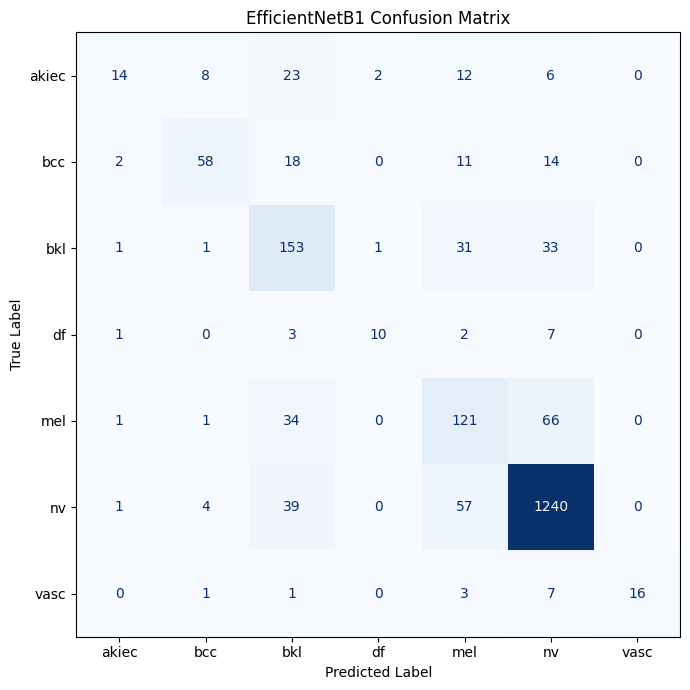

EfficientNetB1 confusion matrix saved.
Path: /kaggle/working/efficientnetb1_confusion_matrix.png


In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_b1,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title("EfficientNetB1 Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()

b1_cm_plot = "/kaggle/working/efficientnetb1_confusion_matrix.png"
plt.savefig(b1_cm_plot, dpi=200, bbox_inches="tight")
plt.show()

print("EfficientNetB1 confusion matrix saved.")
print(f"Path: {b1_cm_plot}")

EfficientNetB2****

In [21]:
MODEL_NAME = "EfficientNetB2"

config = MODEL_CONFIG[MODEL_NAME]
IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

print(f"Current model : {MODEL_NAME}")
print(f"Input size    : {IMG_SIZE}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Training      : {len(train_df)}")
print(f"Validation    : {len(val_df)}")
print(f"Test          : {len(test_df)}")

Current model : EfficientNetB2
Input size    : 260
Batch size    : 24
Training      : 7010
Validation    : 1002
Test          : 2003


In [22]:
from tensorflow.keras.applications.efficientnet import preprocess_input

train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10),
], name="train_augmentation")

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method=tf.image.ResizeMethod.BILINEAR
    )
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

def load_train_image(image_path, label):
    image, label = load_image(image_path, label)
    image = train_augmentation(image, training=True)
    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            load_train_image,
            num_parallel_calls=AUTOTUNE
        )
    else:
        dataset = dataset.map(
            load_image,
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)
test_ds = create_dataset(test_df, training=False)

train_images, train_labels = next(iter(train_ds))
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("EfficientNetB2 pipeline ready")
print("Training batch :", train_images.shape, train_labels.shape)
print("Validation batch:", val_images.shape, val_labels.shape)
print("Test batch     :", test_images.shape, test_labels.shape)
print("Image dtype    :", train_images.dtype)
print("Image range    :", float(tf.reduce_min(train_images)),
      "to", float(tf.reduce_max(train_images)))

assert train_images.shape == (BATCH_SIZE, IMG_SIZE, IMG_SIZE, 3)
assert val_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert test_images.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)

print("B2 pipeline checks passed")
print("Training augmentation enabled only for training")
print("Validation/test remain unaugmented")

EfficientNetB2 pipeline ready
Training batch : (24, 260, 260, 3) (24,)
Validation batch: (24, 260, 260, 3) (24,)
Test batch     : (24, 260, 260, 3) (24,)
Image dtype    : <dtype: 'float32'>
Image range    : 0.0 to 255.0
B2 pipeline checks passed
Training augmentation enabled only for training
Validation/test remain unaugmented


In [23]:
from tensorflow.keras.applications import EfficientNetB2

base_model = EfficientNetB2(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB2_HAM10000"
)

print("EfficientNetB2 model ready")
print("Backbone trainable :", base_model.trainable)
print("Total parameters   :", model.count_params())
print(
    "Trainable parameters:",
    sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
)
print(
    "Non-trainable parameters:",
    sum(tf.keras.backend.count_params(w) for w in model.non_trainable_weights)
)

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB2 model ready
Backbone trainable : False
Total parameters   : 7778432
Trainable parameters: 9863
Non-trainable parameters: 7768569.0


In [24]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB2 compiled")
print("Optimizer         : Adam")
print("Learning rate     : 1e-3")
print("Loss              : Sparse Categorical Crossentropy")
print("Metric            : Accuracy")
print("Backbone frozen   :", not base_model.trainable)

EfficientNetB2 compiled
Optimizer         : Adam
Learning rate     : 1e-3
Loss              : Sparse Categorical Crossentropy
Metric            : Accuracy
Backbone frozen   : True


In [25]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

b2_head_checkpoint = "/kaggle/working/efficientnetb2_head_best.keras"

head_callbacks = [
    ModelCheckpoint(
        b2_head_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=head_callbacks,
    verbose=1
)

print(f"Best head validation accuracy: {max(history_head.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-09-08 07:01:06.771944: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:01:06.917670: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:01:07.323414: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:01:07.467101: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:01:08.359039: E external/local_xla/xla/stream_

292/293 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.6330 - loss: 1.0660

2026-09-08 07:02:54.256058: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:02:54.390756: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:02:54.694643: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:02:54.836903: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:02:55.649856: E external/local_xla/xla/stream_

293/293 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - accuracy: 0.6331 - loss: 1.0655

2026-09-08 07:03:26.232671: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:03:26.376341: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:03:26.733319: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:03:26.876640: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:03:27.725590: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.69661, saving model to /kaggle/working/efficientnetb2_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb2_head_best.keras
293/293 ━━━━━━━━━━━━━━━━━━━━ 174s 461ms/step - accuracy: 0.6735 - loss: 0.9211 - val_accuracy: 0.6966 - val_loss: 0.7745 - learning_rate: 0.0010
Epoch 2/10
292/293 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.7174 - loss: 0.7810
Epoch 2: val_accuracy improved from 0.69661 to 0.72255, saving model to /kaggle/working/efficientnetb2_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb2_head_best.keras
293/293 ━━━━━━━━━━━━━━━━━━━━ 90s 308ms/step - accuracy: 0.7173 - loss: 0.7663 - val_accuracy: 0.7226 - val_loss: 0.7226 - learning_rate: 0.0010
Epoch 3/10
292/293 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.7350 - loss: 0.7141
Epoch 3: val_accuracy did not improve from 0.72255
293/293 ━━━━━━━━━━━━━━━━━━━━ 89s 303ms/step - accuracy: 0.7350 - loss: 0.7180 - val_

In [26]:
model.load_weights(b2_head_checkpoint)

base_model.trainable = True

fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

trainable_count = sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
)

print("EfficientNetB2 fine-tuning setup")
print("Total backbone layers :", len(base_model.layers))
print("Fine-tuning from layer:", fine_tune_from)
print("Trainable parameters  :", trainable_count)

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

b2_checkpoint = "/kaggle/working/efficientnetb2_best.keras"

fine_callbacks = [
    ModelCheckpoint(
        b2_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=fine_callbacks,
    verbose=1
)

print(
    f"Best fine-tuning validation accuracy: "
    f"{max(history_fine.history['val_accuracy']) * 100:.2f}%"
)

EfficientNetB2 fine-tuning setup
Total backbone layers : 340
Fine-tuning from layer: 237
Trainable parameters  : 6164001
Epoch 1/20


2026-09-08 07:18:03.546630: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:18:03.690217: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:18:03.832283: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:18:04.212843: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:18:04.356626: E external/local_xla/xla/stream_

292/293 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.7676 - loss: 0.6359

2026-09-08 07:19:55.808600: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:19:55.951311: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:19:56.195098: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:19:56.338475: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:19:56.480129: E external/local_xla/xla/stream_

293/293 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.7676 - loss: 0.6358
Epoch 1: val_accuracy improved from None to 0.76048, saving model to /kaggle/working/efficientnetb2_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb2_best.keras
293/293 ━━━━━━━━━━━━━━━━━━━━ 172s 444ms/step - accuracy: 0.7730 - loss: 0.6158 - val_accuracy: 0.7605 - val_loss: 0.6091 - learning_rate: 1.0000e-05
Epoch 2/20
292/293 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.7808 - loss: 0.5797
Epoch 2: val_accuracy improved from 0.76048 to 0.77545, saving model to /kaggle/working/efficientnetb2_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb2_best.keras
293/293 ━━━━━━━━━━━━━━━━━━━━ 95s 324ms/step - accuracy: 0.7792 - loss: 0.5784 - val_accuracy: 0.7754 - val_loss: 0.5852 - learning_rate: 1.0000e-05
Epoch 3/20
292/293 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.7945 - loss: 0.5550
Epoch 3: val_accuracy improved from 0.77545 to 0.78144, saving model to

In [27]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

model.load_weights(b2_checkpoint)

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nEfficientNetB2 Test Performance")
print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {accuracy * 100:.2f}%")
print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"Weighted F1     : {f1_weighted * 100:.2f}%")
print(f"Macro F1        : {f1_macro * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

83/84 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8241 - loss: 0.4904

2026-09-08 07:51:13.670316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:51:13.809277: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:51:14.135042: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:51:14.278076: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 07:51:15.080335: E external/local_xla/xla/stream_

84/84 ━━━━━━━━━━━━━━━━━━━━ 19s 224ms/step - accuracy: 0.8233 - loss: 0.4790

EfficientNetB2 Test Performance
Test Loss       : 0.4790
Test Accuracy   : 82.33%
Precision       : 82.84%
Recall          : 82.33%
Weighted F1     : 82.05%
Macro F1        : 68.15%

Classification Report:
              precision    recall  f1-score   support

       akiec     0.9333    0.4308    0.5895        65
         bcc     0.7000    0.7476    0.7230       103
         bkl     0.5887    0.7545    0.6614       220
          df     0.5714    0.6957    0.6275        23
         mel     0.5628    0.4619    0.5074       223
          nv     0.9186    0.9262    0.9224      1341
        vasc     0.9444    0.6071    0.7391        28

    accuracy                         0.8233      2003
   macro avg     0.7456    0.6605    0.6815      2003
weighted avg     0.8284    0.8233    0.8205      2003

Confusion Matrix:
[[  28   11   11    3    9    3    0]
 [   0   77   15    2    3    6    0]
 [   1    7  166    1   19

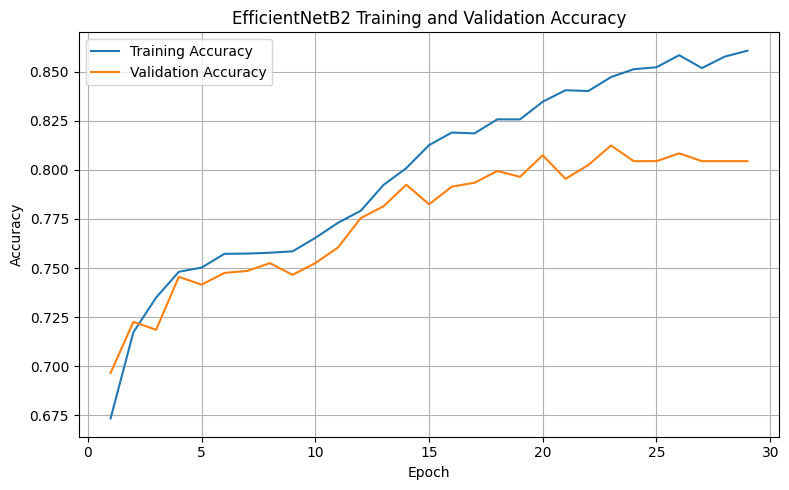

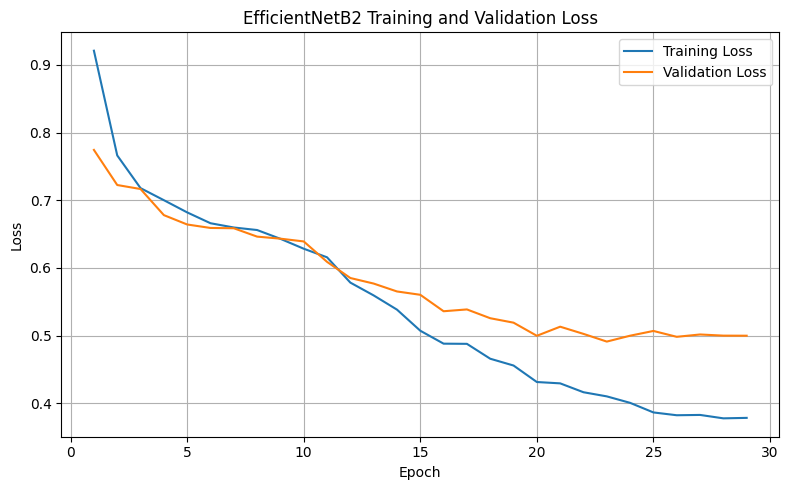

EfficientNetB2 results saved.
Best Validation Accuracy : 81.24%
Test Accuracy            : 82.33%
Macro F1                 : 68.15%
Weighted F1              : 82.05%
Accuracy plot            : /kaggle/working/efficientnetb2_accuracy.png
Loss plot                : /kaggle/working/efficientnetb2_loss.png
Results CSV              : /kaggle/working/efficientnetb2_results.csv


In [28]:
import matplotlib.pyplot as plt
import pandas as pd

train_acc = (
    history_head.history["accuracy"]
    + history_fine.history["accuracy"]
)

val_acc = (
    history_head.history["val_accuracy"]
    + history_fine.history["val_accuracy"]
)

train_loss = (
    history_head.history["loss"]
    + history_fine.history["loss"]
)

val_loss = (
    history_head.history["val_loss"]
    + history_fine.history["val_loss"]
)

epochs = range(1, len(train_acc) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB2 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

b2_acc_plot = "/kaggle/working/efficientnetb2_accuracy.png"
plt.savefig(b2_acc_plot, dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB2 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

b2_loss_plot = "/kaggle/working/efficientnetb2_loss.png"
plt.savefig(b2_loss_plot, dpi=200)
plt.show()

b2_result = {
    "Model": "EfficientNetB2",
    "Parameters": model.count_params(),
    "Input Size": f"{IMG_SIZE}x{IMG_SIZE}",
    "Best Val Accuracy": max(val_acc),
    "Test Accuracy": accuracy,
    "Test Loss": test_loss,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_weighted,
    "Macro F1": f1_macro
}

b2_results_df = pd.DataFrame([b2_result])
b2_results_df.to_csv(
    "/kaggle/working/efficientnetb2_results.csv",
    index=False
)

print("EfficientNetB2 results saved.")
print(f"Best Validation Accuracy : {max(val_acc) * 100:.2f}%")
print(f"Test Accuracy            : {accuracy * 100:.2f}%")
print(f"Macro F1                 : {f1_macro * 100:.2f}%")
print(f"Weighted F1              : {f1_weighted * 100:.2f}%")
print(f"Accuracy plot            : {b2_acc_plot}")
print(f"Loss plot                : {b2_loss_plot}")
print("Results CSV              : /kaggle/working/efficientnetb2_results.csv")

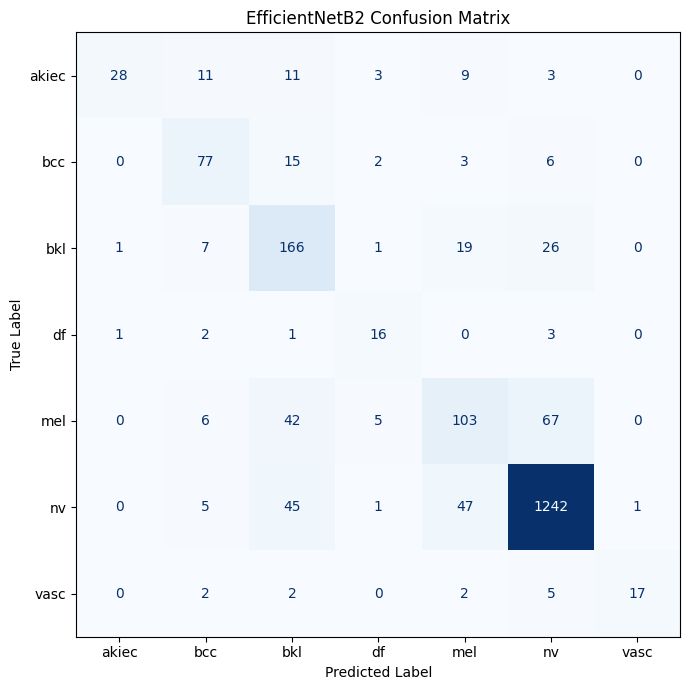

Confusion matrix saved: /kaggle/working/efficientnetb2_confusion_matrix.png


In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=plt.gca(),
    colorbar=False
)

plt.title("EfficientNetB2 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

b2_cm_plot = "/kaggle/working/efficientnetb2_confusion_matrix.png"
plt.savefig(b2_cm_plot, dpi=200, bbox_inches="tight")
plt.show()

print(f"Confusion matrix saved: {b2_cm_plot}")

EfficientNetB3****

In [36]:
MODEL_NAME = "EfficientNetB3"

config = MODEL_CONFIG[MODEL_NAME]
IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

print(f"Current model : {MODEL_NAME}")
print(f"Input size    : {IMG_SIZE}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Training      : {len(train_df)}")
print(f"Validation    : {len(val_df)}")
print(f"Test          : {len(test_df)}")

Current model : EfficientNetB3
Input size    : 300
Batch size    : 16
Training      : 7010
Validation    : 1002
Test          : 2003


In [37]:
from tensorflow.keras.applications import EfficientNetB3

base_model = EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)
x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB3_HAM10000"
)

print("EfficientNetB3 model created.")
print(f"Total parameters: {model.count_params():,}")
print(f"Trainable parameters: {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB3 model created.
Total parameters: 10,794,294
Trainable parameters: 10,759


In [38]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB3 compiled.")
print("Stage 1: Frozen ImageNet backbone")
print("Learning rate: 1e-3")

EfficientNetB3 compiled.
Stage 1: Frozen ImageNet backbone
Learning rate: 1e-3


In [41]:
def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label


train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10)
], name="train_augmentation")


def augment_image(image, label):
    image = train_augmentation(image, training=True)
    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)

train_ds = (
    train_ds
    .shuffle(len(train_df), seed=42, reshuffle_each_iteration=True)
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .map(augment_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

sample_images, sample_labels = next(iter(train_ds))

print("B3 datasets rebuilt successfully.")
print(f"Train batch shape: {sample_images.shape}")
print(f"Validation batches: {tf.data.experimental.cardinality(val_ds).numpy()}")
print(f"Test batches: {tf.data.experimental.cardinality(test_ds).numpy()}")

B3 datasets rebuilt successfully.
Train batch shape: (16, 300, 300, 3)
Validation batches: 63
Test batches: 126


In [43]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()

IMG_SIZE = 300
BATCH_SIZE = 16
NUM_CLASSES = 7

base_model = EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB3_HAM10000"
)

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB3 rebuilt successfully.")
print(f"Input size: {IMG_SIZE} x {IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Total parameters: {model.count_params():,}")
print(f"Trainable parameters: {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")

EfficientNetB3 rebuilt successfully.
Input size: 300 x 300
Batch size: 16
Total parameters: 10,794,294
Trainable parameters: 10,759


In [45]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

b3_head_checkpoint = "/kaggle/working/efficientnetb3_head_best.keras"

head_callbacks = [
    ModelCheckpoint(
        b3_head_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=head_callbacks,
    verbose=1
)

best_head_val_acc = max(history_head.history["val_accuracy"])

print(f"Best B3 head validation accuracy: {best_head_val_acc * 100:.2f}%")
print(f"Head checkpoint: {b3_head_checkpoint}")

Epoch 1/10
438/439 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.7120 - loss: 0.8010

2026-09-08 08:25:58.531329: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:25:58.667261: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:25:58.994204: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:25:59.141841: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:25:59.925926: E external/local_xla/xla/stream_

439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.7120 - loss: 0.8010

2026-09-08 08:26:34.231493: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:26:34.371684: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:26:34.732283: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:26:34.879651: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:26:35.671066: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.71956, saving model to /kaggle/working/efficientnetb3_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb3_head_best.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 169s 384ms/step - accuracy: 0.7096 - loss: 0.8011 - val_accuracy: 0.7196 - val_loss: 0.7850 - learning_rate: 0.0010
Epoch 2/10
438/439 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.7321 - loss: 0.7346
Epoch 2: val_accuracy improved from 0.71956 to 0.72555, saving model to /kaggle/working/efficientnetb3_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb3_head_best.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 119s 270ms/step - accuracy: 0.7281 - loss: 0.7427 - val_accuracy: 0.7255 - val_loss: 0.7550 - learning_rate: 0.0010
Epoch 3/10
438/439 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step - accuracy: 0.7372 - loss: 0.7021
Epoch 3: val_accuracy improved from 0.72555 to 0.73353, saving model to /kaggle/working/efficientnetb3_head_best.keras

Epoch 3: finis

In [46]:
base_model.trainable = True

fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

b3_best_checkpoint = "/kaggle/working/efficientnetb3_best.keras"

fine_tune_callbacks = [
    ModelCheckpoint(
        b3_best_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=fine_tune_callbacks,
    verbose=1
)

best_fine_val_acc = max(history_fine.history["val_accuracy"])

print(f"Fine-tuning from layer: {fine_tune_from}/{len(base_model.layers)}")
print(f"Best B3 fine-tuning validation accuracy: {best_fine_val_acc * 100:.2f}%")
print(f"Best checkpoint: {b3_best_checkpoint}")

Epoch 1/20


2026-09-08 08:45:44.573482: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:45:44.720526: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:45:45.001125: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:45:45.148136: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:45:45.495008: E external/local_xla/xla/stream_

438/439 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.7715 - loss: 0.6347

2026-09-08 08:48:07.743307: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:48:07.891061: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:48:08.143390: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:48:08.290494: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 08:48:08.575245: E external/local_xla/xla/stream_

439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.7715 - loss: 0.6347
Epoch 1: val_accuracy improved from None to 0.76447, saving model to /kaggle/working/efficientnetb3_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb3_best.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 213s 375ms/step - accuracy: 0.7728 - loss: 0.6229 - val_accuracy: 0.7645 - val_loss: 0.6471 - learning_rate: 1.0000e-05
Epoch 2/20
438/439 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.7889 - loss: 0.5643
Epoch 2: val_accuracy improved from 0.76447 to 0.76647, saving model to /kaggle/working/efficientnetb3_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb3_best.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 124s 283ms/step - accuracy: 0.7867 - loss: 0.5725 - val_accuracy: 0.7665 - val_loss: 0.6261 - learning_rate: 1.0000e-05
Epoch 3/20
438/439 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.7919 - loss: 0.5499
Epoch 3: val_accuracy did not improve from 0.76647
439/439 ━━━━━━━━━━━

In [47]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.load_weights("/kaggle/working/efficientnetb3_best.keras")

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

y_true_b3 = np.concatenate([
    y.numpy() for _, y in test_ds
])

y_prob_b3 = model.predict(
    test_ds,
    verbose=1
)

y_pred_b3 = np.argmax(y_prob_b3, axis=1)

precision_b3 = precision_score(
    y_true_b3, y_pred_b3, average="weighted", zero_division=0
)

recall_b3 = recall_score(
    y_true_b3, y_pred_b3, average="weighted", zero_division=0
)

f1_weighted_b3 = f1_score(
    y_true_b3, y_pred_b3, average="weighted", zero_division=0
)

f1_macro_b3 = f1_score(
    y_true_b3, y_pred_b3, average="macro", zero_division=0
)

print("\nEfficientNetB3 Test Performance")
print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {test_accuracy * 100:.2f}%")
print(f"Precision       : {precision_b3 * 100:.2f}%")
print(f"Recall          : {recall_b3 * 100:.2f}%")
print(f"Weighted F1     : {f1_weighted_b3 * 100:.2f}%")
print(f"Macro F1        : {f1_macro_b3 * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true_b3,
        y_pred_b3,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_b3 = confusion_matrix(y_true_b3, y_pred_b3)

print("Confusion Matrix:")
print(cm_b3)

125/126 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8124 - loss: 0.5733

2026-09-08 09:28:47.544060: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:28:47.680719: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:28:48.000342: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:28:48.147815: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:28:48.944819: E external/local_xla/xla/stream_

126/126 ━━━━━━━━━━━━━━━━━━━━ 23s 181ms/step - accuracy: 0.8203 - loss: 0.5394
126/126 ━━━━━━━━━━━━━━━━━━━━ 30s 155ms/step

EfficientNetB3 Test Performance
Test Loss       : 0.5394
Test Accuracy   : 82.03%
Precision       : 83.50%
Recall          : 82.03%
Weighted F1     : 81.90%
Macro F1        : 66.18%

Classification Report:
              precision    recall  f1-score   support

       akiec     0.9000    0.2769    0.4235        65
         bcc     0.7711    0.6214    0.6882       103
         bkl     0.5541    0.7909    0.6517       220
          df     0.7857    0.4783    0.5946        23
         mel     0.5670    0.5695    0.5682       223
          nv     0.9275    0.9165    0.9220      1341
        vasc     0.8696    0.7143    0.7843        28

    accuracy                         0.8203      2003
   macro avg     0.7679    0.6240    0.6618      2003
weighted avg     0.8350    0.8203    0.8190      2003

Confusion Matrix:
[[  18    6   25    1   13    2    0]
 [   1   64   18  

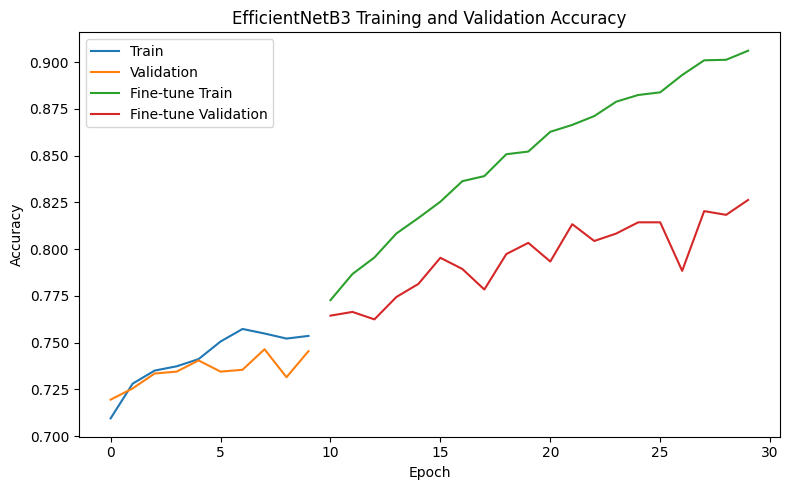

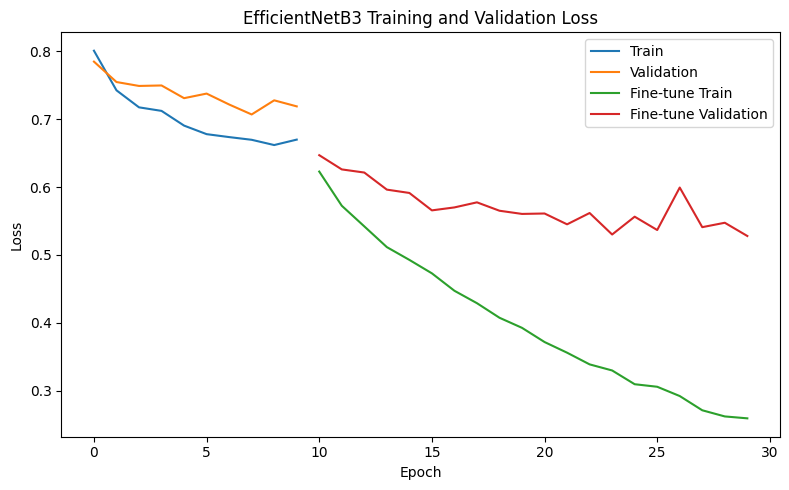

B3 results and training curves saved.
Results: /kaggle/working/efficientnetb3_results.csv
Accuracy plot: /kaggle/working/efficientnetb3_accuracy.png
Loss plot: /kaggle/working/efficientnetb3_loss.png
EfficientNetB3 results saved.
Best Validation Accuracy : 82.63%
Test Accuracy            : 82.03%
Macro F1                 : 66.18%
Weighted F1              : 81.90%
Accuracy plot            : /kaggle/working/efficientnetb3_accuracy.png
Loss plot                : /kaggle/working/efficientnetb3_loss.png
Results CSV              : /kaggle/working/efficientnetb3_results.csv


In [50]:
import pandas as pd
import matplotlib.pyplot as plt

b3_results = pd.DataFrame([{
    "Model": "EfficientNetB3",
    "Parameters": model.count_params(),
    "Input Size": IMG_SIZE,
    "Best Val Accuracy": best_fine_val_acc,
    "Test Accuracy": test_accuracy,
    "Test Loss": test_loss,
    "Precision": precision_b3,
    "Recall": recall_b3,
    "Macro F1": f1_macro_b3,
    "Weighted F1": f1_weighted_b3
}])

b3_results_path = "/kaggle/working/efficientnetb3_results.csv"
b3_results.to_csv(b3_results_path, index=False)

plt.figure(figsize=(8, 5))
plt.plot(history_head.history["accuracy"], label="Train")
plt.plot(history_head.history["val_accuracy"], label="Validation")
plt.plot(
    range(len(history_head.history["accuracy"]),
          len(history_head.history["accuracy"]) + len(history_fine.history["accuracy"])),
    history_fine.history["accuracy"],
    label="Fine-tune Train"
)
plt.plot(
    range(len(history_head.history["val_accuracy"]),
          len(history_head.history["val_accuracy"]) + len(history_fine.history["val_accuracy"])),
    history_fine.history["val_accuracy"],
    label="Fine-tune Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB3 Training and Validation Accuracy")
plt.legend()
plt.tight_layout()

b3_accuracy_plot = "/kaggle/working/efficientnetb3_accuracy.png"
plt.savefig(b3_accuracy_plot, dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_head.history["loss"], label="Train")
plt.plot(history_head.history["val_loss"], label="Validation")
plt.plot(
    range(len(history_head.history["loss"]),
          len(history_head.history["loss"]) + len(history_fine.history["loss"])),
    history_fine.history["loss"],
    label="Fine-tune Train"
)
plt.plot(
    range(len(history_head.history["val_loss"]),
          len(history_head.history["val_loss"]) + len(history_fine.history["val_loss"])),
    history_fine.history["val_loss"],
    label="Fine-tune Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB3 Training and Validation Loss")
plt.legend()
plt.tight_layout()

b3_loss_plot = "/kaggle/working/efficientnetb3_loss.png"
plt.savefig(b3_loss_plot, dpi=200, bbox_inches="tight")
plt.show()

print("B3 results and training curves saved.")
print(f"Results: {b3_results_path}")
print(f"Accuracy plot: {b3_accuracy_plot}")
print(f"Loss plot: {b3_loss_plot}")

print("EfficientNetB3 results saved.")
print(f"Best Validation Accuracy : {best_fine_val_acc * 100:.2f}%")
print(f"Test Accuracy            : {test_accuracy * 100:.2f}%")
print(f"Macro F1                 : {f1_macro_b3 * 100:.2f}%")
print(f"Weighted F1              : {f1_weighted_b3 * 100:.2f}%")
print(f"Accuracy plot            : {b3_accuracy_plot}")
print(f"Loss plot                : {b3_loss_plot}")
print("Results CSV              : /kaggle/working/efficientnetb3_results.csv")

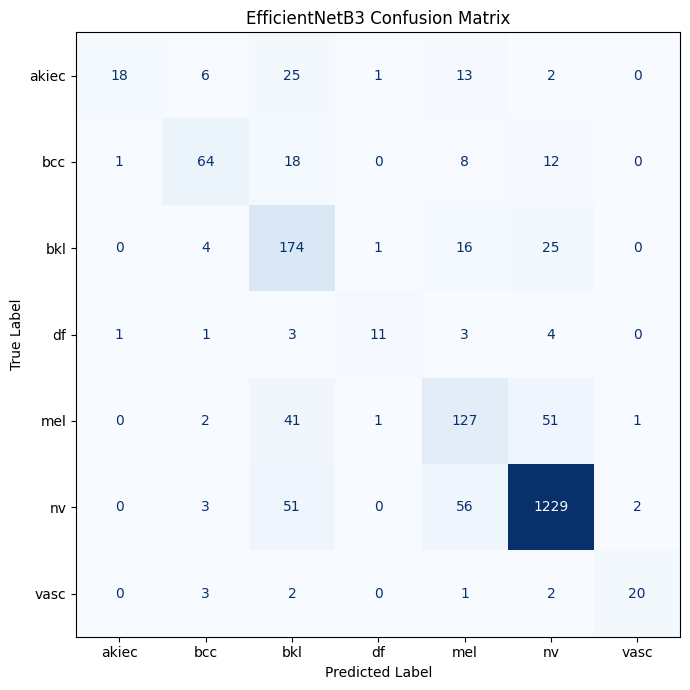

EfficientNetB3 confusion matrix saved.
Path: /kaggle/working/efficientnetb3_confusion_matrix.png


In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_b3,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title("EfficientNetB3 Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()

b3_cm_plot = "/kaggle/working/efficientnetb3_confusion_matrix.png"
plt.savefig(b3_cm_plot, dpi=200, bbox_inches="tight")
plt.show()

print("EfficientNetB3 confusion matrix saved.")
print(f"Path: {b3_cm_plot}")

EfficientNetB4****

In [51]:
MODEL_NAME = "EfficientNetB4"

MODEL_CONFIG = {
    "EfficientNetB0": {"input_size": 224, "batch_size": 32},
    "EfficientNetB1": {"input_size": 240, "batch_size": 32},
    "EfficientNetB2": {"input_size": 260, "batch_size": 24},
    "EfficientNetB3": {"input_size": 300, "batch_size": 16},
    "EfficientNetB4": {"input_size": 380, "batch_size": 8},
    "EfficientNetB5": {"input_size": 456, "batch_size": 4},
    "EfficientNetB6": {"input_size": 528, "batch_size": 2},
    "EfficientNetB7": {"input_size": 600, "batch_size": 1}
}

config = MODEL_CONFIG[MODEL_NAME]

IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

print(f"Model: {MODEL_NAME}")
print(f"Input size: {IMG_SIZE} x {IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")

Model: EfficientNetB4
Input size: 380 x 380
Batch size: 8


In [52]:
def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label


train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10)
], name="train_augmentation")


def augment_image(image, label):
    image = train_augmentation(image, training=True)
    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)

train_ds = (
    train_ds
    .shuffle(len(train_df), seed=42, reshuffle_each_iteration=True)
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .map(augment_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

sample_images, sample_labels = next(iter(train_ds))

print("B4 datasets rebuilt successfully.")
print(f"Train batch shape: {sample_images.shape}")
print(f"Validation batches: {tf.data.experimental.cardinality(val_ds).numpy()}")
print(f"Test batches: {tf.data.experimental.cardinality(test_ds).numpy()}")

B4 datasets rebuilt successfully.
Train batch shape: (8, 380, 380, 3)
Validation batches: 126
Test batches: 251


In [53]:
from tensorflow.keras.applications import EfficientNetB4

tf.keras.backend.clear_session()

base_model = EfficientNetB4(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)
x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB4_HAM10000"
)

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB4 model created.")
print(f"Total parameters: {model.count_params():,}")
print(f"Trainable parameters: {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")

71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB4 model created.
Total parameters: 17,686,374
Trainable parameters: 12,551


In [54]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

b4_head_checkpoint = "/kaggle/working/efficientnetb4_head_best.keras"

head_callbacks = [
    ModelCheckpoint(
        b4_head_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=head_callbacks,
    verbose=1
)

best_head_val_acc = max(history_head.history["val_accuracy"])

print(f"Best B4 head validation accuracy: {best_head_val_acc * 100:.2f}%")
print(f"Head checkpoint: {b4_head_checkpoint}")

Epoch 1/10


2026-09-08 09:40:08.412835: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:40:08.551066: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:40:08.798627: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:40:08.937513: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:40:09.216732: E external/local_xla/xla/stream_

876/877 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.6820 - loss: 0.9301

2026-09-08 09:43:33.576055: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:43:33.710148: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:43:33.901095: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:43:34.035316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 09:43:34.272024: E external/local_xla/xla/stream_

877/877 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.6820 - loss: 0.9300
Epoch 1: val_accuracy improved from None to 0.72754, saving model to /kaggle/working/efficientnetb4_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb4_head_best.keras
877/877 ━━━━━━━━━━━━━━━━━━━━ 286s 267ms/step - accuracy: 0.7007 - loss: 0.8438 - val_accuracy: 0.7275 - val_loss: 0.7635 - learning_rate: 0.0010
Epoch 2/10
876/877 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.7385 - loss: 0.7201
Epoch 2: val_accuracy improved from 0.72754 to 0.74751, saving model to /kaggle/working/efficientnetb4_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb4_head_best.keras
877/877 ━━━━━━━━━━━━━━━━━━━━ 176s 200ms/step - accuracy: 0.7322 - loss: 0.7379 - val_accuracy: 0.7475 - val_loss: 0.7157 - learning_rate: 0.0010
Epoch 3/10
876/877 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.7522 - loss: 0.6833
Epoch 3: val_accuracy did not improve from 0.74751
877/877

In [56]:
from tensorflow.keras.optimizers import Adam

# Load the best B4 head checkpoint
model = tf.keras.models.load_model(b4_head_checkpoint)

# Find the EfficientNetB4 backbone
base_model = next(
    layer for layer in model.layers
    if "efficientnetb4" in layer.name.lower()
)

base_model.trainable = True

# Unfreeze the last 30% of the backbone
fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

b4_best_checkpoint = "/kaggle/working/efficientnetb4_best.keras"

fine_tune_callbacks = [
    ModelCheckpoint(
        b4_best_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print(f"Backbone: {base_model.name}")
print(f"Total backbone layers: {len(base_model.layers)}")
print(f"Fine-tuning from layer: {fine_tune_from}")
print(f"Trainable backbone layers: {sum(layer.trainable for layer in base_model.layers)}")

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=fine_tune_callbacks,
    verbose=1
)

best_fine_val_acc = max(history_fine.history["val_accuracy"])

print(f"Best B4 fine-tuning validation accuracy: {best_fine_val_acc * 100:.2f}%")
print(f"Best model checkpoint: {b4_best_checkpoint}")

Backbone: efficientnetb4
Total backbone layers: 475
Fine-tuning from layer: 332
Trainable backbone layers: 114
Epoch 1/20


2026-09-08 10:17:34.576849: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:17:34.729486: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:17:35.015111: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:17:35.168854: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:17:35.537546: E external/local_xla/xla/stream_

876/877 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.7771 - loss: 0.6081

2026-09-08 10:21:09.256218: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:21:09.409278: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:21:09.676668: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:21:09.830798: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:21:10.140293: E external/local_xla/xla/stream_

877/877 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.7771 - loss: 0.6081
Epoch 1: val_accuracy improved from None to 0.76148, saving model to /kaggle/working/efficientnetb4_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb4_best.keras
877/877 ━━━━━━━━━━━━━━━━━━━━ 302s 278ms/step - accuracy: 0.7796 - loss: 0.5920 - val_accuracy: 0.7615 - val_loss: 0.6437 - learning_rate: 1.0000e-05
Epoch 2/20
876/877 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.8069 - loss: 0.5281
Epoch 2: val_accuracy improved from 0.76148 to 0.78343, saving model to /kaggle/working/efficientnetb4_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb4_best.keras
877/877 ━━━━━━━━━━━━━━━━━━━━ 198s 226ms/step - accuracy: 0.8023 - loss: 0.5327 - val_accuracy: 0.7834 - val_loss: 0.5962 - learning_rate: 1.0000e-05
Epoch 3/20
876/877 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.8246 - loss: 0.4864
Epoch 3: val_accuracy improved from 0.78343 to 0.78842, saving model t

In [57]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the best B4 model
model = tf.keras.models.load_model(b4_best_checkpoint)

# Evaluate on untouched test set
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

# Generate predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("\nEfficientNetB4 Test Results")
print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {test_accuracy * 100:.2f}%")
print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"Macro F1        : {f1_macro * 100:.2f}%")
print(f"Weighted F1     : {f1_weighted * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

250/251 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7992 - loss: 0.5643

2026-09-08 10:59:15.251114: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:59:15.385907: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:59:15.619478: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:59:15.754129: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 10:59:15.999811: E external/local_xla/xla/stream_

251/251 ━━━━━━━━━━━━━━━━━━━━ 52s 140ms/step - accuracy: 0.8073 - loss: 0.5390

EfficientNetB4 Test Results
Test Loss       : 0.5390
Test Accuracy   : 80.73%
Precision       : 83.67%
Recall          : 80.73%
Macro F1        : 63.29%
Weighted F1     : 80.46%

Classification Report:
              precision    recall  f1-score   support

       akiec     1.0000    0.1692    0.2895        65
         bcc     0.7692    0.4854    0.5952       103
         bkl     0.4974    0.8727    0.6337       220
          df     0.6316    0.5217    0.5714        23
         mel     0.5949    0.5202    0.5550       223
          nv     0.9316    0.9045    0.9179      1341
        vasc     0.9200    0.8214    0.8679        28

    accuracy                         0.8073      2003
   macro avg     0.7635    0.6136    0.6329      2003
weighted avg     0.8367    0.8073    0.8046      2003

Confusion Matrix:
[[  11    4   35    0   12    3    0]
 [   0   50   29    3    8   12    1]
 [   0    1  192    1    7  

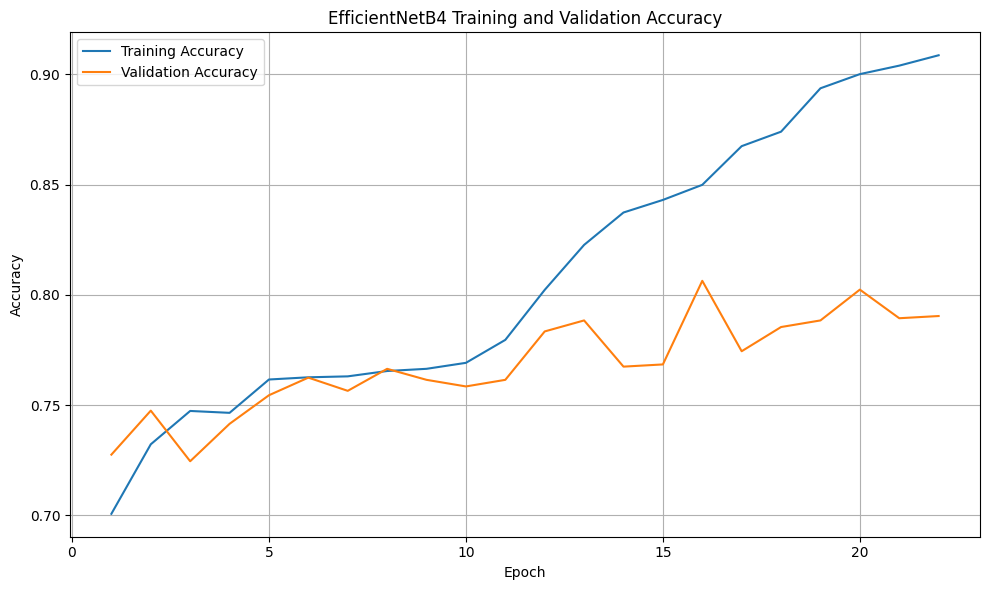

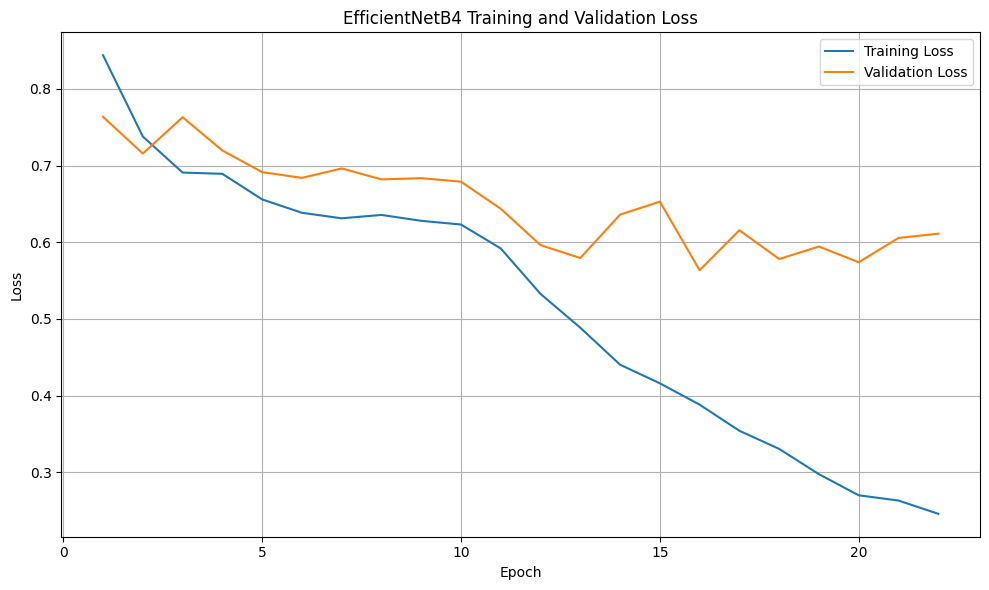

EfficientNetB4 results saved.
Best Validation Accuracy : 80.64%
Test Accuracy            : 80.73%
Macro F1                 : 63.29%
Weighted F1              : 80.46%
Accuracy plot            : /kaggle/working/efficientnetb4_accuracy.png
Loss plot                : /kaggle/working/efficientnetb4_loss.png
Results CSV              : /kaggle/working/efficientnetb4_results.csv


In [58]:
import matplotlib.pyplot as plt

# Combine Stage 1 and Stage 2 histories
head_epochs = len(history_head.history["accuracy"])
fine_epochs = len(history_fine.history["accuracy"])

total_epochs = list(range(1, head_epochs + fine_epochs + 1))

train_accuracy = (
    history_head.history["accuracy"]
    + history_fine.history["accuracy"]
)

val_accuracy = (
    history_head.history["val_accuracy"]
    + history_fine.history["val_accuracy"]
)

train_loss = (
    history_head.history["loss"]
    + history_fine.history["loss"]
)

val_loss = (
    history_head.history["val_loss"]
    + history_fine.history["val_loss"]
)

# Accuracy graph
plt.figure(figsize=(10, 6))
plt.plot(total_epochs, train_accuracy, label="Training Accuracy")
plt.plot(total_epochs, val_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB4 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

b4_accuracy_plot = "/kaggle/working/efficientnetb4_accuracy.png"
plt.savefig(b4_accuracy_plot, dpi=300, bbox_inches="tight")
plt.show()

# Loss graph
plt.figure(figsize=(10, 6))
plt.plot(total_epochs, train_loss, label="Training Loss")
plt.plot(total_epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB4 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

b4_loss_plot = "/kaggle/working/efficientnetb4_loss.png"
plt.savefig(b4_loss_plot, dpi=300, bbox_inches="tight")
plt.show()

# B4 results summary
print("EfficientNetB4 results saved.")
print(f"Best Validation Accuracy : {best_fine_val_acc * 100:.2f}%")
print(f"Test Accuracy            : {test_accuracy * 100:.2f}%")
print(f"Macro F1                 : {f1_macro * 100:.2f}%")
print(f"Weighted F1              : {f1_weighted * 100:.2f}%")
print(f"Accuracy plot            : {b4_accuracy_plot}")
print(f"Loss plot                : {b4_loss_plot}")
print("Results CSV              : /kaggle/working/efficientnetb4_results.csv")

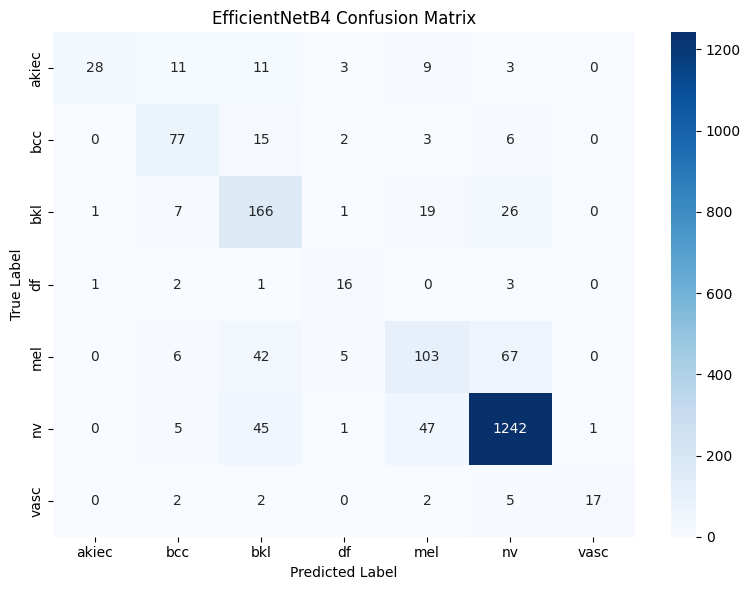

Confusion Matrix saved: /kaggle/working/efficientnetb4_confusion_matrix.png


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNetB4 Confusion Matrix")
plt.tight_layout()

b4_cm_plot = "/kaggle/working/efficientnetb4_confusion_matrix.png"
plt.savefig(b4_cm_plot, dpi=300, bbox_inches="tight")
plt.show()

print(f"Confusion Matrix saved: {b4_cm_plot}")

EfficientNetB5****

In [60]:
MODEL_NAME = "EfficientNetB5"

config = MODEL_CONFIG[MODEL_NAME]

IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

print(f"Model      : {MODEL_NAME}")
print(f"Input Size : {IMG_SIZE} × {IMG_SIZE}")
print(f"Batch Size : {BATCH_SIZE}")

Model      : EfficientNetB5
Input Size : 456 × 456
Batch Size : 4


In [61]:
def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label


train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10)
], name="train_augmentation")


def augment_image(image, label):
    image = train_augmentation(image, training=True)
    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)
train_ds = train_ds.shuffle(
    len(train_df),
    seed=42,
    reshuffle_each_iteration=True
)
train_ds = train_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)
train_ds = train_ds.map(
    augment_image,
    num_parallel_calls=AUTOTUNE
)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(AUTOTUNE)


val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)
val_ds = val_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)
val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(AUTOTUNE)


test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)
test_ds = test_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(AUTOTUNE)


images, labels = next(iter(train_ds))

print("Train batch shape :", images.shape)
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches      :", tf.data.experimental.cardinality(test_ds).numpy())
print("Image dtype       :", images.dtype)
print("Image range       :", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Train batch shape : (4, 456, 456, 3)
Validation batches: 251
Test batches      : 501
Image dtype       : <dtype: 'float32'>
Image range       : 0.0 to 255.0


In [62]:
tf.keras.backend.clear_session()
gc.collect()

from tensorflow.keras.applications import EfficientNetB5

base_model = EfficientNetB5(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print(f"Total parameters     : {model.count_params():,}")
print(f"Trainable parameters: {sum(tf.keras.backend.count_params(w) for w in model.trainable_weights):,}")

115263384/115263384 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb5 (Functional)     │ (None, 15, 15, 2048)   │    28,513,527 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,527,870 (108.83 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 28,513,527 (108.77 MB)

Total parameters     : 28,527,870
Trainable parameters: 14,343


In [63]:
b5_head_checkpoint = "/kaggle/working/efficientnetb5_head_best.keras"

callbacks_head = [
    keras.callbacks.ModelCheckpoint(
        b5_head_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks_head,
    verbose=1
)

best_head_val_acc = max(history_head.history["val_accuracy"])

print("\nEfficientNetB5 Stage 1 completed.")
print(f"Best Head Validation Accuracy: {best_head_val_acc * 100:.2f}%")
print(f"Best Head Checkpoint        : {b5_head_checkpoint}")

Epoch 1/10


2026-09-08 11:07:16.703800: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:07:16.851512: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:07:18.295444: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:07:18.432927: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:07:18.697471: E external/local_xla/xla/stream_

1752/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.6864 - loss: 0.9031

2026-09-08 11:11:40.474070: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:11:40.612528: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:11:42.053712: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:11:42.188569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:11:42.443560: E external/local_xla/xla/stream_

1753/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.6865 - loss: 0.9030
Epoch 1: val_accuracy improved from None to 0.71257, saving model to /kaggle/working/efficientnetb5_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb5_head_best.keras
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 369s 176ms/step - accuracy: 0.7113 - loss: 0.8182 - val_accuracy: 0.7126 - val_loss: 0.7704 - learning_rate: 0.0010
Epoch 2/10
1752/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.7473 - loss: 0.7008
Epoch 2: val_accuracy improved from 0.71257 to 0.75349, saving model to /kaggle/working/efficientnetb5_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb5_head_best.keras
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 249s 142ms/step - accuracy: 0.7445 - loss: 0.7026 - val_accuracy: 0.7535 - val_loss: 0.6610 - learning_rate: 0.0010
Epoch 3/10
1752/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.7650 - loss: 0.6636
Epoch 3: val_accuracy did not improve from 0.753

In [64]:
# Load the best Stage 1 checkpoint
model = tf.keras.models.load_model(b5_head_checkpoint)

# Find the EfficientNetB5 backbone
base_model = next(
    layer for layer in model.layers
    if "efficientnetb5" in layer.name.lower()
)

base_model.trainable = True

# Fine-tune the last 30% of the backbone
fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

b5_best_checkpoint = "/kaggle/working/efficientnetb5_best.keras"

callbacks_fine = [
    keras.callbacks.ModelCheckpoint(
        b5_best_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_fine,
    verbose=1
)

best_fine_val_acc = max(history_fine.history["val_accuracy"])

print("\nEfficientNetB5 Stage 2 completed.")
print(f"Best Fine-tuning Validation Accuracy: {best_fine_val_acc * 100:.2f}%")
print(f"Best Fine-tuned Checkpoint         : {b5_best_checkpoint}")

Epoch 1/20


2026-09-08 11:52:26.129997: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:52:26.287264: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:52:26.444276: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:52:26.743553: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:52:26.903680: E external/local_xla/xla/stream_

1752/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.7867 - loss: 0.5911

2026-09-08 11:57:46.231818: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:57:46.390416: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:57:46.674656: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:57:46.838502: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 11:57:46.996307: E external/local_xla/xla/stream_

1753/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.7867 - loss: 0.5911
Epoch 1: val_accuracy improved from None to 0.77944, saving model to /kaggle/working/efficientnetb5_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb5_best.keras
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 434s 208ms/step - accuracy: 0.7959 - loss: 0.5661 - val_accuracy: 0.7794 - val_loss: 0.5791 - learning_rate: 1.0000e-05
Epoch 2/20
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8208 - loss: 0.4759
Epoch 2: val_accuracy improved from 0.77944 to 0.79541, saving model to /kaggle/working/efficientnetb5_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb5_best.keras
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 309s 176ms/step - accuracy: 0.8240 - loss: 0.4746 - val_accuracy: 0.7954 - val_loss: 0.5541 - learning_rate: 1.0000e-05
Epoch 3/20
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8512 - loss: 0.4140
Epoch 3: val_accuracy did not improve from 0.79541
1753/1753

In [65]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model = tf.keras.models.load_model(b5_best_checkpoint)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nEfficientNetB5 - TEST RESULTS")
print(f"Test Loss        : {test_loss:.4f}")
print(f"Test Accuracy    : {test_accuracy * 100:.2f}%")
print(f"Precision        : {precision * 100:.2f}%")
print(f"Recall           : {recall * 100:.2f}%")
print(f"Weighted F1      : {f1_weighted * 100:.2f}%")
print(f"Macro F1         : {f1_macro * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

500/501 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.8363 - loss: 0.5030

2026-09-08 13:12:03.864786: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 13:12:04.006860: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 13:12:05.453693: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 13:12:05.588440: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 13:12:05.843601: E external/local_xla/xla/stream_

501/501 ━━━━━━━━━━━━━━━━━━━━ 78s 116ms/step - accuracy: 0.8427 - loss: 0.4712

EfficientNetB5 - TEST RESULTS
Test Loss        : 0.4712
Test Accuracy    : 84.27%
Precision        : 86.58%
Recall           : 84.27%
Weighted F1      : 84.78%
Macro F1         : 73.30%

Classification Report:
              precision    recall  f1-score   support

       akiec     0.8235    0.4308    0.5657        65
         bcc     0.8701    0.6505    0.7444       103
         bkl     0.6547    0.8273    0.7309       220
          df     0.5938    0.8261    0.6909        23
         mel     0.5537    0.7399    0.6334       223
          nv     0.9608    0.8956    0.9271      1341
        vasc     0.7647    0.9286    0.8387        28

    accuracy                         0.8427      2003
   macro avg     0.7459    0.7570    0.7330      2003
weighted avg     0.8658    0.8427    0.8478      2003


Confusion Matrix:
[[  28    3   23    1   10    0    0]
 [   5   67   13    4    8    3    3]
 [   1    1  182   

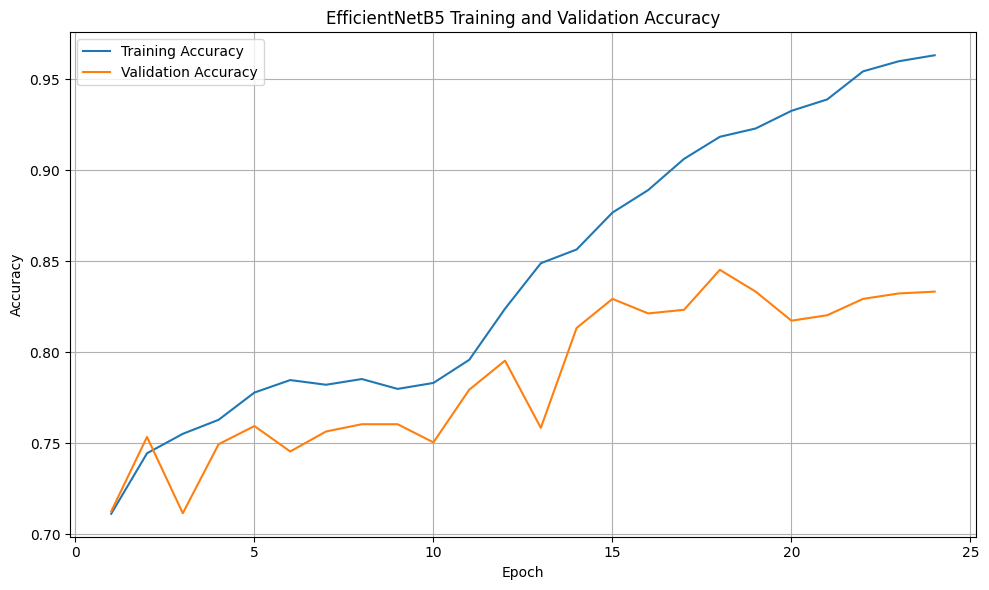

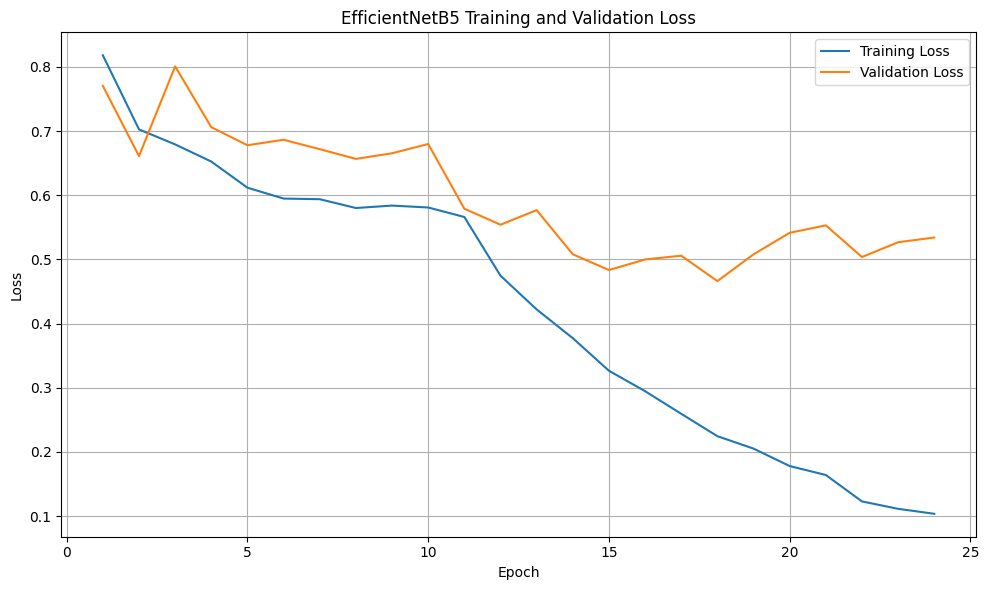

Accuracy plot saved: /kaggle/working/efficientnetb5_accuracy.png
Loss plot saved: /kaggle/working/efficientnetb5_loss.png

EfficientNetB5 - TEST RESULTS
Test Loss        : 0.4712
Test Accuracy    : 84.27%
Precision        : 86.58%
Recall           : 84.27%
Weighted F1      : 84.78%
Macro F1         : 73.30%


In [66]:
import matplotlib.pyplot as plt

head_epochs = len(history_head.history["accuracy"])
fine_epochs = len(history_fine.history["accuracy"])

total_epochs = list(range(1, head_epochs + fine_epochs + 1))

train_accuracy = (
    history_head.history["accuracy"] +
    history_fine.history["accuracy"]
)

val_accuracy = (
    history_head.history["val_accuracy"] +
    history_fine.history["val_accuracy"]
)

train_loss = (
    history_head.history["loss"] +
    history_fine.history["loss"]
)

val_loss = (
    history_head.history["val_loss"] +
    history_fine.history["val_loss"]
)

# Accuracy graph
plt.figure(figsize=(10, 6))

plt.plot(
    total_epochs,
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    total_epochs,
    val_accuracy,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB5 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

b5_accuracy_plot = "/kaggle/working/efficientnetb5_accuracy.png"
plt.savefig(b5_accuracy_plot, dpi=300, bbox_inches="tight")
plt.show()

# Loss graph
plt.figure(figsize=(10, 6))

plt.plot(
    total_epochs,
    train_loss,
    label="Training Loss"
)

plt.plot(
    total_epochs,
    val_loss,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB5 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

b5_loss_plot = "/kaggle/working/efficientnetb5_loss.png"
plt.savefig(b5_loss_plot, dpi=300, bbox_inches="tight")
plt.show()

print(f"Accuracy plot saved: {b5_accuracy_plot}")
print(f"Loss plot saved: {b5_loss_plot}")

print("\nEfficientNetB5 - TEST RESULTS")
print(f"Test Loss        : {test_loss:.4f}")
print(f"Test Accuracy    : {test_accuracy * 100:.2f}%")
print(f"Precision        : {precision * 100:.2f}%")
print(f"Recall           : {recall * 100:.2f}%")
print(f"Weighted F1      : {f1_weighted * 100:.2f}%")
print(f"Macro F1         : {f1_macro * 100:.2f}%")

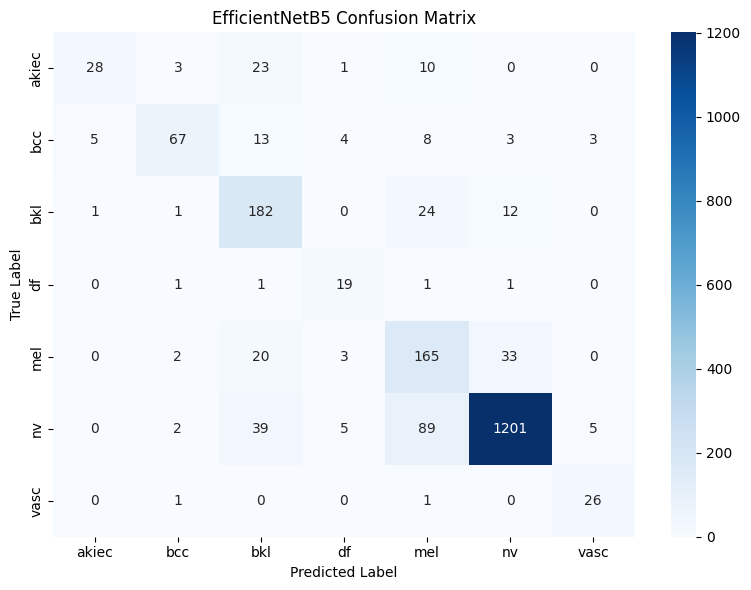

Confusion Matrix saved: /kaggle/working/efficientnetb5_confusion_matrix.png


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNetB5 Confusion Matrix")
plt.tight_layout()

b5_cm_plot = "/kaggle/working/efficientnetb5_confusion_matrix.png"
plt.savefig(b5_cm_plot, dpi=300, bbox_inches="tight")
plt.show()

print(f"Confusion Matrix saved: {b5_cm_plot}")

In [68]:
import pandas as pd
from sklearn.metrics import classification_report

# Classification report
b5_report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

b5_report_df = pd.DataFrame(b5_report).transpose()

b5_report_path = "/kaggle/working/efficientnetb5_classification_report.csv"
b5_report_df.to_csv(b5_report_path)

# Main results
b5_results = pd.DataFrame([{
    "Model": "EfficientNetB5",
    "Parameters": model.count_params(),
    "Input Size": "456x456",
    "Best Validation Accuracy": best_fine_val_acc,
    "Test Loss": test_loss,
    "Test Accuracy": test_accuracy,
    "Precision": precision,
    "Recall": recall,
    "Macro F1": f1_macro,
    "Weighted F1": f1_weighted
}])

b5_results_path = "/kaggle/working/efficientnetb5_results.csv"
b5_results.to_csv(b5_results_path, index=False)

print("EfficientNetB5 results saved.")
print(f"Best Validation Accuracy : {best_fine_val_acc * 100:.2f}%")
print(f"Test Accuracy            : {test_accuracy * 100:.2f}%")
print(f"Macro F1                 : {f1_macro * 100:.2f}%")
print(f"Weighted F1              : {f1_weighted * 100:.2f}%")
print(f"Classification Report    : {b5_report_path}")
print(f"Results CSV              : {b5_results_path}")
print(f"Confusion Matrix         : {b5_cm_plot}")
print(f"Accuracy Plot            : {b5_accuracy_plot}")
print(f"Loss Plot                : {b5_loss_plot}")

EfficientNetB5 results saved.
Best Validation Accuracy : 84.53%
Test Accuracy            : 84.27%
Macro F1                 : 73.30%
Weighted F1              : 84.78%
Classification Report    : /kaggle/working/efficientnetb5_classification_report.csv
Results CSV              : /kaggle/working/efficientnetb5_results.csv
Confusion Matrix         : /kaggle/working/efficientnetb5_confusion_matrix.png
Accuracy Plot            : /kaggle/working/efficientnetb5_accuracy.png
Loss Plot                : /kaggle/working/efficientnetb5_loss.png


EfficientNetB6.****

In [8]:
MODEL_NAME = "EfficientNetB6"

config = MODEL_CONFIG[MODEL_NAME]

IMG_SIZE = config["input_size"]
BATCH_SIZE = config["batch_size"]

print(f"Model      : {MODEL_NAME}")
print(f"Input Size : {IMG_SIZE} × {IMG_SIZE}")
print(f"Batch Size : {BATCH_SIZE}")

Model      : EfficientNetB6
Input Size : 528 × 528
Batch Size : 2


In [9]:
def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label


train_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomContrast(0.10)
], name="train_augmentation")


def augment_image(image, label):
    image = train_augmentation(image, training=True)
    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)
train_ds = train_ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.map(augment_image, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.shuffle(1000, seed=42)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(AUTOTUNE)


val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)
val_ds = val_ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(AUTOTUNE)


test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)
test_ds = test_ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(AUTOTUNE)


sample_images, sample_labels = next(iter(train_ds))

print("EfficientNetB6 pipeline ready.")
print("Train batch shape :", sample_images.shape)
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches      :", tf.data.experimental.cardinality(test_ds).numpy())
print("Image dtype       :", sample_images.dtype)
print("Image range       :", float(tf.reduce_min(sample_images)),
      "to", float(tf.reduce_max(sample_images)))

I0000 00:00:1788888378.576710      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788888378.579687      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


EfficientNetB6 pipeline ready.
Train batch shape : (2, 528, 528, 3)
Validation batches: 501
Test batches      : 1002
Image dtype       : <dtype: 'float32'>
Image range       : 8.520423889160156 to 247.38209533691406


In [11]:
tf.keras.backend.clear_session()
gc.collect()

from tensorflow.keras.applications import EfficientNetB6

base_model = EfficientNetB6(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 528, 528, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb6 (Functional)     │ (None, 17, 17, 2304)   │    40,960,143 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2304)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │        16,135 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,976,278 (156.31 MB)

 Trainable params: 16,135 (63.03 KB)

 Non-trainable params: 40,960,143 (156.25 MB)

In [12]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

b6_head_checkpoint = "/kaggle/working/efficientnetb6_head_best.keras"

head_checkpoint = ModelCheckpoint(
    b6_head_checkpoint,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

head_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

head_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        head_checkpoint,
        head_early_stopping,
        head_reduce_lr
    ]
)

best_head_val_acc = max(history_head.history["val_accuracy"])

print(f"\nBest Stage 1 Validation Accuracy: {best_head_val_acc * 100:.2f}%")
print(f"Checkpoint: {b6_head_checkpoint}")

Epoch 1/10


2026-09-08 17:28:32.726510: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 17:28:32.885480: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 17:28:34.305903: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 17:28:34.457157: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 17:28:34.724603: E external/local_xla/xla/stream_

3505/3505 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.6872 - loss: 0.9133
Epoch 1: val_accuracy improved from None to 0.62575, saving model to /kaggle/working/efficientnetb6_head_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb6_head_best.keras
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 444s 98ms/step - accuracy: 0.7009 - loss: 0.8416 - val_accuracy: 0.6257 - val_loss: 1.0306 - learning_rate: 0.0010
Epoch 2/10
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7372 - loss: 0.7351
Epoch 2: val_accuracy improved from 0.62575 to 0.75549, saving model to /kaggle/working/efficientnetb6_head_best.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb6_head_best.keras
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 355s 91ms/step - accuracy: 0.7348 - loss: 0.7383 - val_accuracy: 0.7555 - val_loss: 0.7495 - learning_rate: 0.0010
Epoch 3/10
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7558 - loss: 0.6904
Epoch 3: val_accuracy did not improve from 0.75549
35

In [13]:
model = tf.keras.models.load_model(b6_head_checkpoint)

base_model = next(
    layer for layer in model.layers
    if "efficientnetb6" in layer.name.lower()
)

base_model.trainable = True

fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

b6_best_checkpoint = "/kaggle/working/efficientnetb6_best.keras"

fine_checkpoint = ModelCheckpoint(
    b6_best_checkpoint,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

fine_early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

fine_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        fine_checkpoint,
        fine_early_stopping,
        fine_reduce_lr
    ]
)

best_fine_val_acc = max(history_fine.history["val_accuracy"])

print(f"\nBest Stage 2 Validation Accuracy: {best_fine_val_acc * 100:.2f}%")
print(f"Checkpoint: {b6_best_checkpoint}")

Epoch 1/20


2026-09-08 18:11:27.932385: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 18:11:28.072094: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 18:11:28.329969: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 18:11:28.497192: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 18:11:28.807610: E external/local_xla/xla/stream_

3505/3505 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.7716 - loss: 0.6322
Epoch 1: val_accuracy improved from None to 0.79441, saving model to /kaggle/working/efficientnetb6_best.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb6_best.keras
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 575s 132ms/step - accuracy: 0.7815 - loss: 0.6030 - val_accuracy: 0.7944 - val_loss: 0.5745 - learning_rate: 1.0000e-05
Epoch 2/20
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8238 - loss: 0.4893
Epoch 2: val_accuracy did not improve from 0.79441
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 481s 127ms/step - accuracy: 0.8250 - loss: 0.4722 - val_accuracy: 0.7525 - val_loss: 0.6515 - learning_rate: 1.0000e-05
Epoch 3/20
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.8463 - loss: 0.4042
Epoch 3: val_accuracy did not improve from 0.79441
3505/3505 ━━━━━━━━━━━━━━━━━━━━ 480s 127ms/step - accuracy: 0.8531 - loss: 0.3959 - val_accuracy: 0.7705 - val_loss: 0.6256 - learning_rate: 1.0000e-0

In [14]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model = tf.keras.models.load_model(b6_best_checkpoint)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nEfficientNetB6 - TEST RESULTS")
print(f"Test Loss        : {test_loss:.4f}")
print(f"Test Accuracy    : {test_accuracy * 100:.2f}%")
print(f"Precision        : {precision * 100:.2f}%")
print(f"Recall           : {recall * 100:.2f}%")
print(f"Weighted F1      : {f1_weighted * 100:.2f}%")
print(f"Macro F1         : {f1_macro * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

1001/1002 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8403 - loss: 0.6525

2026-09-08 20:54:00.492553: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 20:54:00.643614: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 20:54:02.129837: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 20:54:02.276099: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-08 20:54:02.535231: E external/local_xla/xla/stream_

1002/1002 ━━━━━━━━━━━━━━━━━━━━ 109s 85ms/step - accuracy: 0.8497 - loss: 0.6140

EfficientNetB6 - TEST RESULTS
Test Loss        : 0.6140
Test Accuracy    : 84.97%
Precision        : 86.93%
Recall           : 84.97%
Weighted F1      : 85.20%
Macro F1         : 73.87%

Classification Report:
              precision    recall  f1-score   support

       akiec       0.86      0.37      0.52        65
         bcc       0.87      0.66      0.75       103
         bkl       0.62      0.88      0.73       220
          df       0.82      0.61      0.70        23
         mel       0.60      0.72      0.65       223
          nv       0.95      0.91      0.93      1341
        vasc       0.92      0.86      0.89        28

    accuracy                           0.85      2003
   macro avg       0.81      0.71      0.74      2003
weighted avg       0.87      0.85      0.85      2003


Confusion Matrix:
[[  24    4   22    1   12    2    0]
 [   2   68   20    0    8    5    0]
 [   2    1  194 

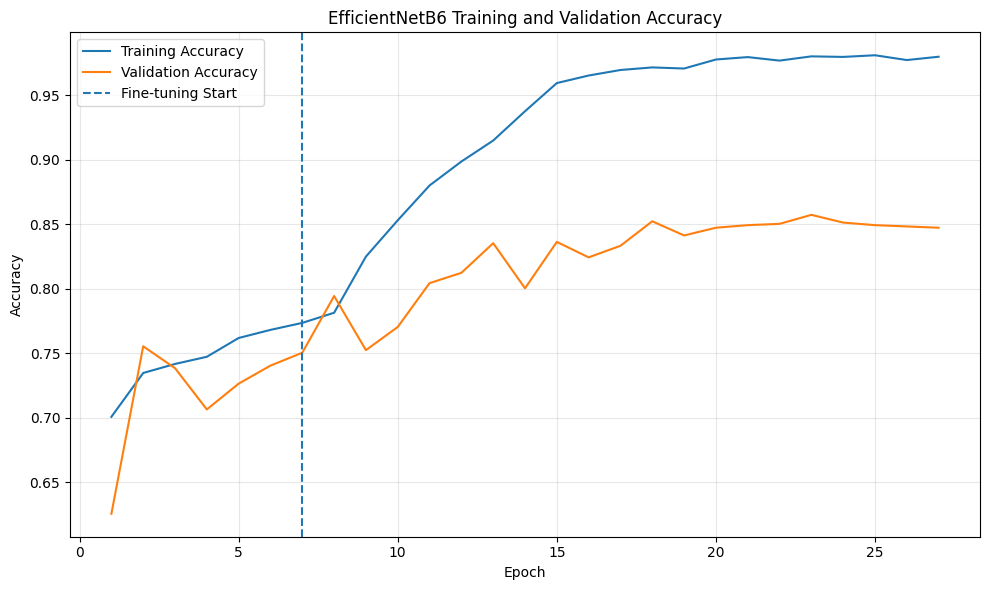

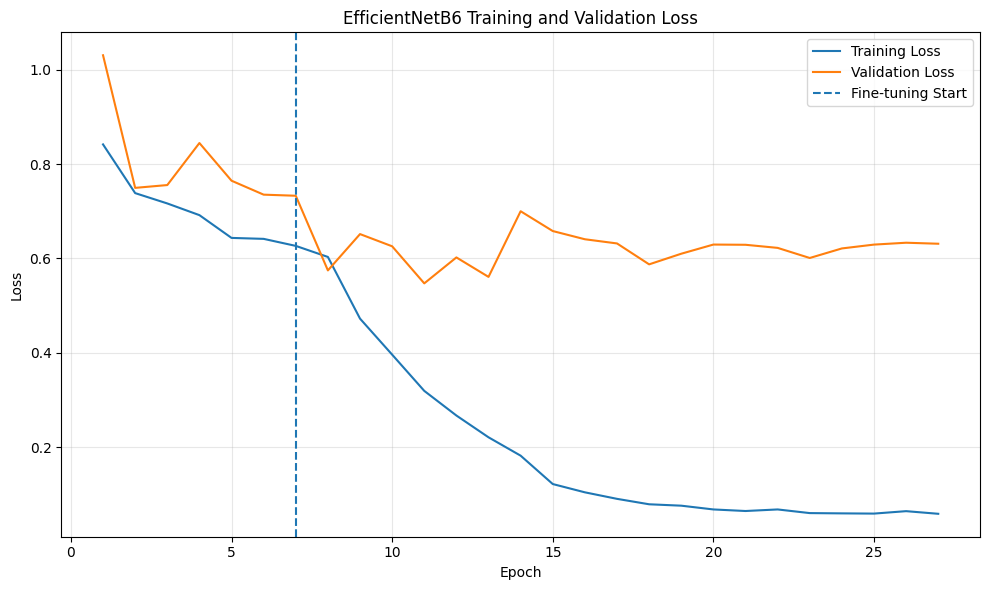

Accuracy plot saved: /kaggle/working/efficientnetb6_accuracy.png
Loss plot saved: /kaggle/working/efficientnetb6_loss.png


In [15]:
import matplotlib.pyplot as plt

head_epochs = len(history_head.history["accuracy"])
fine_epochs = len(history_fine.history["accuracy"])

total_epochs = list(range(1, head_epochs + fine_epochs + 1))

train_accuracy = (
    history_head.history["accuracy"]
    + history_fine.history["accuracy"]
)

val_accuracy = (
    history_head.history["val_accuracy"]
    + history_fine.history["val_accuracy"]
)

train_loss = (
    history_head.history["loss"]
    + history_fine.history["loss"]
)

val_loss = (
    history_head.history["val_loss"]
    + history_fine.history["val_loss"]
)

plt.figure(figsize=(10, 6))
plt.plot(total_epochs, train_accuracy, label="Training Accuracy")
plt.plot(total_epochs, val_accuracy, label="Validation Accuracy")
plt.axvline(
    x=head_epochs,
    linestyle="--",
    label="Fine-tuning Start"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB6 Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

b6_accuracy_plot = "/kaggle/working/efficientnetb6_accuracy.png"
plt.savefig(b6_accuracy_plot, dpi=300, bbox_inches="tight")
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(total_epochs, train_loss, label="Training Loss")
plt.plot(total_epochs, val_loss, label="Validation Loss")
plt.axvline(
    x=head_epochs,
    linestyle="--",
    label="Fine-tuning Start"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB6 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

b6_loss_plot = "/kaggle/working/efficientnetb6_loss.png"
plt.savefig(b6_loss_plot, dpi=300, bbox_inches="tight")
plt.show()

print(f"Accuracy plot saved: {b6_accuracy_plot}")
print(f"Loss plot saved: {b6_loss_plot}")

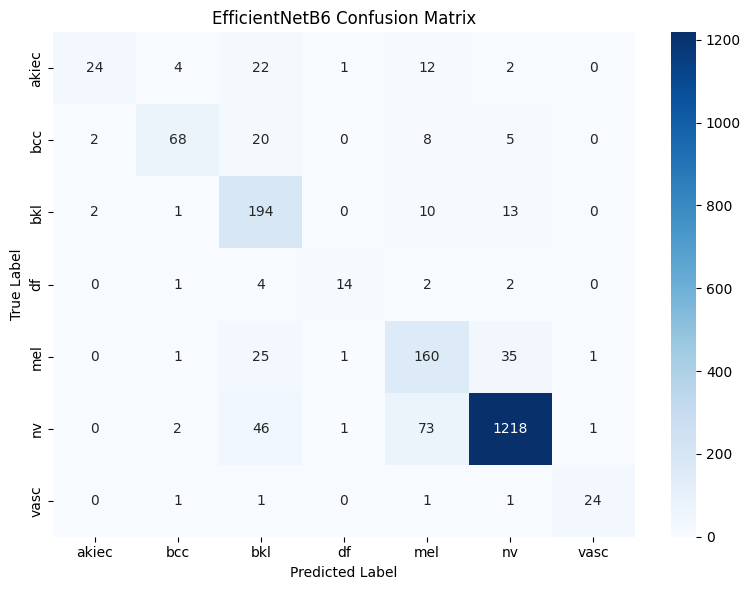

Confusion Matrix saved: /kaggle/working/efficientnetb6_confusion_matrix.png


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNetB6 Confusion Matrix")
plt.tight_layout()

b6_cm_plot = "/kaggle/working/efficientnetb6_confusion_matrix.png"

plt.savefig(
    b6_cm_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Confusion Matrix saved: {b6_cm_plot}")

In [17]:
import os

for f in sorted(os.listdir("/kaggle/working")):
    if "efficientnet" in f.lower():
        print(f)

efficientnetb6_accuracy.png
efficientnetb6_best.keras
efficientnetb6_confusion_matrix.png
efficientnetb6_head_best.keras
efficientnetb6_loss.png


In [18]:
import pandas as pd
from sklearn.metrics import classification_report

b6_report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

b6_report_df = pd.DataFrame(b6_report).transpose()

b6_report_path = "/kaggle/working/efficientnetb6_classification_report.csv"
b6_report_df.to_csv(b6_report_path)

b6_results = pd.DataFrame([{
    "Model": "EfficientNetB6",
    "Parameters": model.count_params(),
    "Input Size": "528x528",
    "Best Validation Accuracy": best_fine_val_acc,
    "Test Loss": test_loss,
    "Test Accuracy": test_accuracy,
    "Precision": precision,
    "Recall": recall,
    "Macro F1": f1_macro,
    "Weighted F1": f1_weighted
}])

b6_results_path = "/kaggle/working/efficientnetb6_results.csv"
b6_results.to_csv(b6_results_path, index=False)

print("B6 files saved successfully")
print(f"Classification Report: {b6_report_path}")
print(f"Results CSV: {b6_results_path}")
print()
print(b6_results.to_string(index=False))

B6 files saved successfully
Classification Report: /kaggle/working/efficientnetb6_classification_report.csv
Results CSV: /kaggle/working/efficientnetb6_results.csv

         Model  Parameters Input Size  Best Validation Accuracy  Test Loss  Test Accuracy  Precision   Recall  Macro F1  Weighted F1
EfficientNetB6    40976278    528x528                  0.857285   0.614001       0.849725   0.869332 0.849725  0.738708     0.852004


FINAL EFFICIENTNET COMPARISON
 Rank          Model  Parameters Input Size  Best Validation Accuracy (%)  Test Loss  Test Accuracy (%)  Precision (%)  Recall (%)  Macro F1 (%)  Weighted F1 (%)
    1 EfficientNetB6    40976278    528x528                         85.73     0.6140              84.97          86.93       84.97         73.87            85.20
    2 EfficientNetB5    28527870    456x456                         84.53     0.4712              84.27          86.58       84.27         73.30            84.78
    3 EfficientNetB2     7778432    260x260                         81.24     0.4790              82.33          82.84       82.33         68.15            82.05
    4 EfficientNetB3    10794294    300x300                         82.63     0.5394              82.03          83.50       82.03         66.18            81.90
    5 EfficientNetB0     4058538    224x224                         81.24     0.5260              81.13          81.31       81.13         63.34            80.3

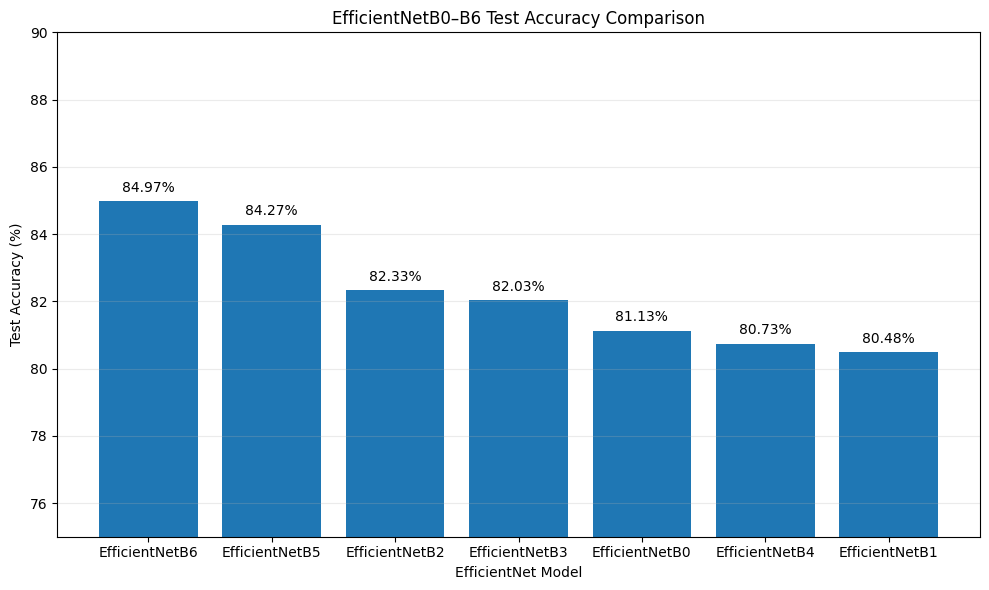

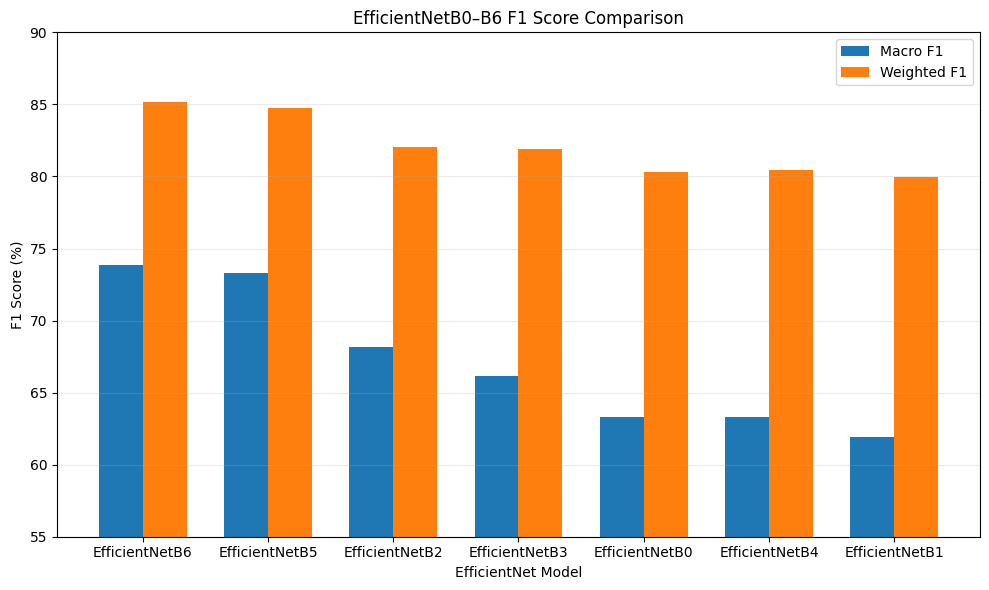


Graphs saved:
/kaggle/working/efficientnet_test_accuracy_comparison.png
/kaggle/working/efficientnet_f1_comparison.png

BEST MODEL
Model                : EfficientNetB6
Test Accuracy        : 84.97%
Macro F1             : 73.87%
Weighted F1          : 85.20%
Parameters           : 40,976,278
Input Size           : 528x528


In [19]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_data = [
    {
        "Model": "EfficientNetB0",
        "Parameters": 4058538,
        "Input Size": "224x224",
        "Best Validation Accuracy (%)": 81.24,
        "Test Loss": 0.5260,
        "Test Accuracy (%)": 81.13,
        "Precision (%)": 81.31,
        "Recall (%)": 81.13,
        "Macro F1 (%)": 63.34,
        "Weighted F1 (%)": 80.31
    },
    {
        "Model": "EfficientNetB1",
        "Parameters": 6584206,
        "Input Size": "240x240",
        "Best Validation Accuracy (%)": 80.94,
        "Test Loss": 0.5388,
        "Test Accuracy (%)": 80.48,
        "Precision (%)": 80.99,
        "Recall (%)": 80.48,
        "Macro F1 (%)": 61.92,
        "Weighted F1 (%)": 79.99
    },
    {
        "Model": "EfficientNetB2",
        "Parameters": 7778432,
        "Input Size": "260x260",
        "Best Validation Accuracy (%)": 81.24,
        "Test Loss": 0.4790,
        "Test Accuracy (%)": 82.33,
        "Precision (%)": 82.84,
        "Recall (%)": 82.33,
        "Macro F1 (%)": 68.15,
        "Weighted F1 (%)": 82.05
    },
    {
        "Model": "EfficientNetB3",
        "Parameters": 10794294,
        "Input Size": "300x300",
        "Best Validation Accuracy (%)": 82.63,
        "Test Loss": 0.5394,
        "Test Accuracy (%)": 82.03,
        "Precision (%)": 83.50,
        "Recall (%)": 82.03,
        "Macro F1 (%)": 66.18,
        "Weighted F1 (%)": 81.90
    },
    {
        "Model": "EfficientNetB4",
        "Parameters": 17686374,
        "Input Size": "380x380",
        "Best Validation Accuracy (%)": 80.64,
        "Test Loss": 0.5390,
        "Test Accuracy (%)": 80.73,
        "Precision (%)": 83.67,
        "Recall (%)": 80.73,
        "Macro F1 (%)": 63.29,
        "Weighted F1 (%)": 80.46
    },
    {
        "Model": "EfficientNetB5",
        "Parameters": 28527870,
        "Input Size": "456x456",
        "Best Validation Accuracy (%)": 84.53,
        "Test Loss": 0.4712,
        "Test Accuracy (%)": 84.27,
        "Precision (%)": 86.58,
        "Recall (%)": 84.27,
        "Macro F1 (%)": 73.30,
        "Weighted F1 (%)": 84.78
    },
    {
        "Model": "EfficientNetB6",
        "Parameters": 40976278,
        "Input Size": "528x528",
        "Best Validation Accuracy (%)": 85.73,
        "Test Loss": 0.6140,
        "Test Accuracy (%)": 84.97,
        "Precision (%)": 86.93,
        "Recall (%)": 84.97,
        "Macro F1 (%)": 73.87,
        "Weighted F1 (%)": 85.20
    }
]

comparison_df = pd.DataFrame(comparison_data)

# Rank models using test accuracy, then Macro F1, then Weighted F1
comparison_df = comparison_df.sort_values(
    by=["Test Accuracy (%)", "Macro F1 (%)", "Weighted F1 (%)"],
    ascending=False
).reset_index(drop=True)

comparison_df.insert(0, "Rank", range(1, len(comparison_df) + 1))

# Save final comparison CSV
csv_path = "/kaggle/working/efficientnet_final_comparison.csv"
comparison_df.to_csv(csv_path, index=False)

print("FINAL EFFICIENTNET COMPARISON")
print("=" * 70)
print(comparison_df.to_string(index=False))

print("\nFiles:")
print(csv_path)

# Test Accuracy comparison
plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)

plt.xlabel("EfficientNet Model")
plt.ylabel("Test Accuracy (%)")
plt.title("EfficientNetB0–B6 Test Accuracy Comparison")
plt.ylim(75, 90)
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(
    bars,
    comparison_df["Test Accuracy (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

accuracy_graph = "/kaggle/working/efficientnet_test_accuracy_comparison.png"
plt.savefig(accuracy_graph, dpi=300, bbox_inches="tight")
plt.show()

# F1-score comparison
plt.figure(figsize=(10, 6))

x = range(len(comparison_df))
width = 0.35

plt.bar(
    [i - width / 2 for i in x],
    comparison_df["Macro F1 (%)"],
    width,
    label="Macro F1"
)

plt.bar(
    [i + width / 2 for i in x],
    comparison_df["Weighted F1 (%)"],
    width,
    label="Weighted F1"
)

plt.xticks(list(x), comparison_df["Model"])
plt.xlabel("EfficientNet Model")
plt.ylabel("F1 Score (%)")
plt.title("EfficientNetB0–B6 F1 Score Comparison")
plt.ylim(55, 90)
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

f1_graph = "/kaggle/working/efficientnet_f1_comparison.png"
plt.savefig(f1_graph, dpi=300, bbox_inches="tight")
plt.show()

print("\nGraphs saved:")
print(accuracy_graph)
print(f1_graph)

# Best model
best_model = comparison_df.iloc[0]

print("\n" + "=" * 70)
print("BEST MODEL")
print("=" * 70)
print(f"Model                : {best_model['Model']}")
print(f"Test Accuracy        : {best_model['Test Accuracy (%)']:.2f}%")
print(f"Macro F1             : {best_model['Macro F1 (%)']:.2f}%")
print(f"Weighted F1          : {best_model['Weighted F1 (%)']:.2f}%")
print(f"Parameters           : {best_model['Parameters']:,}")
print(f"Input Size           : {best_model['Input Size']}")

In [20]:
import os

print("Important saved files:")
print("=" * 70)

for file in sorted(os.listdir("/kaggle/working/")):
    if (
        file.endswith(".keras")
        or file.endswith(".csv")
        or file.endswith(".png")
    ):
        path = os.path.join("/kaggle/working/", file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{file:<55} {size_mb:8.2f} MB")

Important saved files:
efficientnet_f1_comparison.png                              0.10 MB
efficientnet_final_comparison.csv                           0.00 MB
efficientnet_test_accuracy_comparison.png                   0.13 MB
efficientnetb6_accuracy.png                                 0.19 MB
efficientnetb6_best.keras                                 406.24 MB
efficientnetb6_classification_report.csv                    0.00 MB
efficientnetb6_confusion_matrix.png                         0.14 MB
efficientnetb6_head_best.keras                            158.65 MB
efficientnetb6_loss.png                                     0.17 MB
efficientnetb6_results.csv                                  0.00 MB


In [21]:
import os
import zipfile

backup_files = [
    "efficientnet_final_comparison.csv",
    "efficientnet_test_accuracy_comparison.png",
    "efficientnet_f1_comparison.png",
    "efficientnetb6_best.keras",
    "efficientnetb6_head_best.keras",
    "efficientnetb6_results.csv",
    "efficientnetb6_classification_report.csv",
    "efficientnetb6_confusion_matrix.png",
    "efficientnetb6_accuracy.png",
    "efficientnetb6_loss.png"
]

zip_path = "/kaggle/working/efficientnet_project_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in backup_files:
        filepath = f"/kaggle/working/{filename}"
        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)

print("Backup created successfully:")
print(zip_path)

size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"Backup size: {size_mb:.2f} MB")

Backup created successfully:
/kaggle/working/efficientnet_project_backup.zip
Backup size: 520.64 MB
